# Resistance and community recovery: an organized exploration

**Main question:** Does having more resistant bacteria before antibiotic exposure help a community retain diversity and composition, and does it matter which strains carry resistance?

This notebook reorganizes the uploaded analysis. It preserves the original biological model, random seeds, carrier assignments, treatment protocol and numerical simulation settings. It combines repeated calculations into shared tables and uses short plotting calls. It does **not** add Gillespie noise or change the experimental design.

**Run:** Open this notebook and choose **Restart Kernel → Run All**. NumPy, pandas, SciPy, Matplotlib ≥3.7 and IPython are required. The model is embedded, so no separate model file is needed. Matching simulations in the previous `baseline_resistance_correlation_results/cache` folder are reused. New tables and figures go to `organized_resistance_results`; if no cache exists, the simulations run automatically.

**Reading order**

1. Understand the experiment and metric scales.
2. Look at community trajectories and diversity.
3. Compare resistant/susceptible biomass before and after treatment.
4. Examine resistance–recovery relationships.
5. Identify the strains driving restructuring and inspect their traits.
6. Use the supplementary controls and correlation analysis to test the interpretation.

Every figure section explains **what is calculated**, **how to read it**, and **what the results show**. Detailed model/helper code is collapsed by default, but remains available for inspection. The short plotting cells can be edited independently.


## A. The experiment in plain English

The same **57 strains** appear in every simulation. Their intrinsic growth rates, underlying susceptibility values and equal starting abundances stay fixed. We vary the number of resistant strains: **0, 1, 5, 10, 20, 30, 40, 57**.

For each intermediate count, there are **10 resistance-assignment orders**. An order is a shuffled list of strain identities. The first k strains become carriers when the count is k; raising the count adds carriers without removing earlier ones. The orders change *who* is resistant, not the underlying strain traits. The zero- and all-resistant cases each have one possible assignment and are included once.

Each configuration has antibiotic-treated and untreated versions. The dynamics are deterministic: repeating the exact same configuration gives the same trajectory. Between-order variation is **carrier-identity variation**, not technical replicate noise.

| Time | What happens |
|---|---|
| 0 h | Inoculate at total 0.005 OD, divided equally among strains |
| 0–4 h | Grow without antibiotics |
| **4 h** | **Pretreatment baseline**, immediately before adding drug |
| 6 h | Early response, two hours after drug addition |
| 24 h | End of exposure; the sampled community is **before dilution** |
| Immediately after 24 h | 1:100 transfer into fresh drug-free medium |
| 48 h | Recovery endpoint |

All strains consume the same nutrient. Carriers pay a constant growth cost, are immune to antibiotic killing and degrade drug in the shared medium. Thus intrinsic traits stay fixed, but effective maximum growth changes when a strain receives resistance.

**Two important distinctions**

- Increasing carrier count also increases initial resistant biomass. This design does not isolate distribution while holding resistant biomass constant.
- The model does not track enzyme concentration. Resistant-carrier biomass is a **proxy for β-lactamase capacity**, not measured gene or protein abundance.

**Sampling precision:** the uploaded notebook uses the original stored trajectories. When an exact requested time is absent, it uses the nearest saved point. In particular, the original 48 h record can actually be 47.9 h. This reorganization preserves that behavior rather than silently changing the simulations. `samples.actual_hour` records the actual value and the timing audit below reports it.


## B. Metric guide: what the numbers mean

Let $N_i(t)$ be strain i's absolute biomass in OD, $B(t)=\sum _iN_i(t)$ the total, and $p_i(t)=N_i(t)/B(t)$ its relative abundance.

| Metric | Calculation | Meaning and scale |
|---|---|---|
| Total biomass | $B=\sum _iN_i$ | Actual community size in OD; not normalized |
| Resistant biomass | $B_R=\sum _{i:\mathrm{carrier}}N_i$ | Actual biomass belonging to resistant strains |
| Resistant percentage | $100B_R/B$ | 0–100%; who makes up the community, not its total size |
| Shannon diversity | $H=-\sum _{p_i>0}p_i\ln  p_i$ | 0 for one strain; maximum $\ln (57)\approx 4.04$ for equal abundances |
| Gini–Simpson diversity | $S=1-\sum _i p_i^2$ | Probability that two independent cell selections belong to different strains; 0 to $1-1/57\approx 0.982$ here |
| Shannon retention | $H(t)/H(4)$ | 1 unchanged; below 1 lower; above 1 higher. Not the fraction of strains surviving |
| Simpson retention | $S(t)/S(4)$ | Same interpretation, using Gini–Simpson |
| Bray–Curtis to baseline | $BC(t,4)=\frac12\sum _i\lvert p_i(t)-p_i(4)\rvert $ | 0 identical composition; 1 no overlap. Higher = more restructuring |
| Biomass versus control | $B_T(t)/B_C(t)$ | 1 means equal biomass to the matched untreated community |

T means treated; C means untreated. Relative compositions are normalized before calculating Bray–Curtis, so it measures composition independently of total biomass.

**Do not equate these metrics.** A community can lose most of its biomass while keeping similar proportions and diversity. Conversely, biomass can recover while different strains dominate. Low Bray–Curtis is not evidence of high biomass.

**Empty communities:** if total biomass is zero, relative composition and diversity are undefined. They are not entered as zero diversity or zero dissimilarity. Retention is also undefined if its baseline index is zero. Detected strain counts use the original model's relative threshold; non-detection is not automatically extinction.


In [1]:
from pathlib import Path
from dataclasses import replace
from contextlib import contextmanager
import sys, types, hashlib, json, colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter
from scipy.optimize import curve_fit
from scipy.stats import spearmanr, pearsonr
from IPython.display import display, Markdown

# Original experiment settings: preserved from the uploaded notebook.
TRAIT_SEED = 42
ASSIGNMENT_SEED = 21000
N_ORDERS = 10
COUNTS = [0, 1, 5, 10, 20, 30, 40, 57]
DOSE = 50.0
SAMPLE_HOURS = [6.0, 24.0, 48.0]
BOOTSTRAPS = 1000
BOOTSTRAP_SEED = 817
RECOMPUTE = False

# Display choices; these do not change the simulations.
BASELINE_HOUR, ENDPOINT_HOUR = 4.0, 48.0
DISPLAY_ORDER, DISPLAY_COUNT = 0, 5
TOP_N = 12
STATUS_COUNT, MIN_PER_STATUS = 20, 2

OUT = Path('organized_resistance_results')
FIGURES = OUT / 'figures'
CACHE = Path('baseline_resistance_correlation_results') / 'cache'
OUT.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100,
                     'axes.spines.top': False, 'axes.spines.right': False})


## C. Load the model, create the design, and run the checks

The next collapsed cell contains the original model and the explicit-carrier initialization helper. The biological equations are unchanged. It verifies the source hash, checks that assigning the original carrier mask reproduces the original initialization, and runs the built-in model checks. The complete fixed-trait table is saved; only its first rows are displayed.


In [2]:
ORIGINAL_MODEL_SOURCE = '"""\nPre-existing resistance and post-antibiotic community recovery\n==============================================================\n\nA minimal model of the barcoded E. coli community experiment: grow the community,\ntreat it with carbenicillin, dilute into fresh drug-free medium, let it recover, and\nmeasure how much of the community came back.\n\nEverything needed is in this one file:\n\n    BASELINE          every parameter, with units\n    run(**changes)    one matched experiment -> all readouts\n    sweep(...)        one parameter over a list of values\n    grid(...)         two parameters over a rectangle\n    check()           sanity checks; run once per session, not on import\n\nA notebook needs nothing but:\n\n    from resilience_model import run, sweep, grid, BASELINE, check\n    r = run(growth_mean=0.2)          # anything not named keeps its baseline value\n    r.metrics                         # one row of readouts\n    df = sweep("n_resistant", [0, 1, 2, 4, 8, 16])\n\nSee README.md for the assumptions, their justification, and the tested ranges.\n\nUnits: time in hours, biomass in OD, drug in ug/ml of carbenicillin.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field, replace\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.integrate import solve_ivp\n\n__all__ = ["BASELINE", "Params", "run", "sweep", "grid", "check", "Result",\n           "TESTED_RANGES", "SAMPLE_HOURS"]\n\nSAMPLE_HOURS = (4.0, 6.0, 24.0, 48.0)   # when the experiment samples\n\n\n# --------------------------------------------------------------------------- parameters\n@dataclass(frozen=True)\nclass Params:\n    """Every parameter of the model. `BASELINE` is the default instance.\n\n    Drug concentrations are in ug/ml of carbenicillin, so `dose` is the number the\n    protocol specifies and `km` is TEM-1\'s measured Michaelis constant in the same unit.\n    """\n    # --- community -------------------------------------------------------------\n    seed: int = 42                  # fixes every strain trait; change to test robustness\n    n_strains: int = 57             # barcoded library size\n    focal_index: int = 29           # k30, the strain that carries the resistance gene\n\n    # --- growth ----------------------------------------------------------------\n    growth_mean: float = 0.55       # 1/h, mean maximum growth rate across strains\n    growth_cv: float = 0.08         # strain-to-strain spread in maximum growth rate\n    food: float = 1.0               # OD-equivalents of nutrient in fresh medium\n    half_saturation: float = 0.05   # OD-equivalents; Monod constant for nutrient uptake\n    death_rate: float = 0.004       # 1/h, constant death rate (fed or starving)\n\n    # --- resistance ------------------------------------------------------------\n    n_resistant: int = 1            # how many strains carry the gene; 0 = sensitive community\n    focal_multiplier: float = 1.0   # starting biomass of k30 relative to the others (1x or 10x)\n    resistance_cost: float = 0.05   # fractional loss of maximum growth rate for a carrier\n\n    # --- antibiotic ------------------------------------------------------------\n    dose: float = 50.0              # ug/ml carbenicillin added at the start of treatment\n    gamma: float = 2.5              # max killing rate, as a multiple of the cell\'s current growth\n    hill: float = 2.0               # Hill coefficient of the killing response\n    susceptible_ic50: float = 5.0   # ug/ml, median IC50 of the susceptible strains\n    ic50_cv: float = 0.70           # strain-to-strain spread in IC50 (lognormal sd)\n    vmax: float = 10000.0           # ug/ml/h per OD of resistant biomass, at saturation\n    km: float = 5.3                 # ug/ml; TEM-1 Km for carbenicillin (14 uM)\n\n    # --- protocol --------------------------------------------------------------\n    initial_biomass: float = 0.005  # total OD at inoculation, split equally across strains\n    pregrowth_h: float = 4.0        # drug-free growth before treatment\n    treatment_h: float = 20.0       # with drug\n    dilution: float = 100.0         # fold dilution at transfer into fresh medium\n    recovery_h: float = 24.0        # drug-free growth after transfer\n\n    # --- measurement -----------------------------------------------------------\n    cells_per_OD: float = 1e9       # sets the extinction floor at one cell\n    detection_rel: float = 1e-4     # relative abundance below which a barcode is not counted\n\n    # --- numerics --------------------------------------------------------------\n    dt_out: float = 0.1             # output spacing, h (does not affect the solution)\n    rtol: float = 1e-8\n    atol: float = 1e-10\n\n    @property\n    def floor(self) -> float:\n        """Extinction threshold: one cell."""\n        return 1.0 / self.cells_per_OD\n\n\nBASELINE = Params()\n\n\n# --------------------------------------------------------------------------- community\n@lru_cache(maxsize=256)\ndef _traits(seed: int, n: int, growth_mean: float, growth_cv: float,\n            susceptible_ic50: float, ic50_cv: float):\n    """Per-strain maximum growth rate and IC50.\n\n    Strains differ in these two properties and nothing else: they are near-isogenic\n    single-gene deletions of one parent, competing for the same nutrient. Both draws\n    depend only on the seed, so changing any other parameter compares the same strains.\n    """\n    rng = np.random.default_rng(seed)\n    s = np.sqrt(np.log1p(growth_cv ** 2))\n    mu = growth_mean * np.exp(s * rng.standard_normal(n) - s ** 2 / 2)\n    ic50 = susceptible_ic50 * np.exp(ic50_cv * rng.standard_normal(n) - ic50_cv ** 2 / 2)\n    return mu, ic50\n\n\n@lru_cache(maxsize=256)\ndef _carriers(seed: int, n: int, focal_index: int, k: int):\n    """Which strains carry the resistance gene.\n\n    k30 is always first, then others in a fixed order from a dedicated random stream,\n    so the sets are nested: raising k adds carriers without reshuffling the existing\n    ones, and the draw never disturbs the trait sampling.\n    """\n    mask = np.zeros(n, bool)\n    if k <= 0:\n        return mask\n    others = np.array([i for i in range(n) if i != focal_index])\n    order = np.random.default_rng(seed + 991).permutation(others)\n    mask[np.r_[focal_index, order[:k - 1]].astype(int)] = True\n    return mask\n\n\ndef community(p: Params):\n    """Strain traits, carrier mask and starting biomass for one parameter set."""\n    mu, ic50 = _traits(p.seed, p.n_strains, p.growth_mean, p.growth_cv,\n                       p.susceptible_ic50, p.ic50_cv)\n    carrier = _carriers(p.seed, p.n_strains, p.focal_index, p.n_resistant)\n    mu = mu * (1 - p.resistance_cost * carrier)   # the enzyme is expressed constantly, so\n                                                  # its cost is a constant growth penalty\n    n0 = np.full(p.n_strains, p.initial_biomass / p.n_strains)\n    n0[p.focal_index] *= p.focal_multiplier\n    return mu, ic50, carrier, n0\n\n\n# --------------------------------------------------------------------------- dynamics\ndef _rates(N, R, a, mu, ic50, carrier, p: Params):\n    """Per-strain growth and killing, nutrient draw-down, and drug degradation."""\n    R = max(R, 0.0)\n    a = max(a, 0.0)\n    g = mu * R / (p.half_saturation + R)              # Monod growth on the shared nutrient\n    if a > 0.0:\n        x = (a / ic50) ** p.hill\n        kill = p.gamma * (x / (1.0 + x)) * g          # beta-lactam killing needs growth\n        kill = np.where(carrier, 0.0, kill)           # carriers are immune at these doses\n    else:\n        kill = np.zeros_like(g)\n    dR = -float(np.sum(N * g))                        # 1 OD of biomass consumes 1 unit of food\n    resistant_biomass = float(np.sum(N[carrier]))\n    da = -p.vmax * resistant_biomass * a / (p.km + a) # saturating degradation by live carriers\n    return g, kill, dR, da\n\n\ndef _segment(N0, R0, a0, t0, t1, mu, ic50, carrier, p: Params, alive):\n    """Integrate one phase, stopping whenever a strain crosses the one-cell floor.\n\n    Biomass is integrated in log space so that abundances spanning many orders of\n    magnitude stay accurate; a strain that reaches one cell is removed for good.\n    """\n    floor_log = np.log(p.floor)\n    grid_t = np.arange(t0, t1 + p.dt_out / 2, p.dt_out)\n    ts, Ns, Rs, as_, deaths = [], [], [], [], []\n    death_total = 0.0\n    N, R, a = N0.copy(), R0, a0\n\n    while t0 < t1 - 1e-12:\n        idx = np.flatnonzero(alive)\n        if idx.size == 0:\n            te = grid_t[(grid_t >= t0) & (grid_t <= t1)]\n            for t in te:\n                ts.append(t); Ns.append(N.copy()); Rs.append(R); as_.append(a)\n                deaths.append(death_total)\n            break\n\n        def rhs(t, y):\n            Nl = np.zeros_like(N)\n            Nl[idx] = np.exp(y[:idx.size])\n            g, kill, dR, da = _rates(Nl, y[-3], y[-2], mu, ic50, carrier, p)\n            dlog = g[idx] - p.death_rate - kill[idx]\n            dloss = float(np.sum(Nl * (p.death_rate + kill)))\n            return np.r_[dlog, dR, da, dloss]\n\n        def make_event(j):\n            def ev(t, y):\n                return y[j] - floor_log\n            ev.terminal = True\n            ev.direction = -1\n            return ev\n\n        y0 = np.r_[np.log(np.maximum(N[idx], p.floor * 1e-3)), R, a, death_total]\n        te = np.minimum(grid_t[(grid_t >= t0) & (grid_t <= t1)], t1)\n        sol = solve_ivp(rhs, (t0, t1), y0, method="LSODA", t_eval=te,\n                        events=[make_event(j) for j in range(idx.size)],\n                        rtol=p.rtol, atol=p.atol, dense_output=False)\n        if not sol.success:\n            raise RuntimeError(sol.message)\n\n        for k, t in enumerate(sol.t):\n            Nk = np.zeros_like(N)\n            Nk[idx] = np.exp(sol.y[:idx.size, k])\n            ts.append(float(t)); Ns.append(Nk); Rs.append(float(sol.y[-3, k]))\n            as_.append(float(sol.y[-2, k])); deaths.append(float(sol.y[-1, k]))\n\n        if sol.status == 1:                                  # a strain hit the floor\n            t0 = float(sol.t_events[[len(e) > 0 for e in sol.t_events].index(True)][0])\n            yend = np.concatenate([e for e in sol.y_events if len(e)])[0]\n            N = np.zeros_like(N); N[idx] = np.exp(yend[:idx.size])\n            R, a, death_total = float(yend[-3]), float(yend[-2]), float(yend[-1])\n            hit = idx[np.isclose(yend[:idx.size], floor_log, atol=1e-9)]\n            if hit.size == 0:\n                hit = idx[[int(np.argmin(yend[:idx.size]))]]\n            death_total += float(np.sum(N[hit]))             # the last cell is accounted for\n            alive[hit] = False\n            N[hit] = 0.0\n        else:\n            t0 = t1\n            N = Ns[-1].copy() if Ns else N\n            R, a, death_total = Rs[-1], as_[-1], deaths[-1]\n\n    return (np.array(ts), np.array(Ns), np.array(Rs), np.array(as_),\n            np.array(deaths), N, R, a, death_total)\n\n\ndef simulate(p: Params) -> dict:\n    """Pre-growth -> treatment -> 1:dilution transfer -> recovery."""\n    mu, ic50, carrier, n0 = community(p)\n    alive = n0 > p.floor\n    t_treat = p.pregrowth_h\n    t_transfer = p.pregrowth_h + p.treatment_h\n    t_end = t_transfer + p.recovery_h\n\n    T, NN, RR, AA, DD = [], [], [], [], []\n    removed = 0.0\n\n    # phase 1: drug-free pre-growth\n    ts, Ns, Rs, as_, dd, N, R, a, death = _segment(\n        n0, p.food, 0.0, 0.0, t_treat, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_); DD += list(dd)\n\n    # phase 2: drug added\n    a = p.dose\n    ts, Ns, Rs, as_, dd, N, R, a, death2 = _segment(\n        N, R, a, t_treat, t_transfer, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death2\n\n    # transfer: 1:dilution into fresh drug-free medium\n    pre_transfer = N.copy()\n    removed += R          # the spent medium, with whatever nutrient is left in it, is discarded\n    N = N / p.dilution\n    removed += float(np.sum(pre_transfer) - np.sum(N))\n    gone = (N < p.floor) & alive\n    removed += float(np.sum(N[gone]))\n    N[gone] = 0.0\n    alive = alive & ~gone\n    post_transfer = N.copy()\n\n    # phase 3: recovery in fresh medium\n    ts, Ns, Rs, as_, dd, N, R, a, death3 = _segment(\n        N, p.food, 0.0, t_transfer, t_end, mu, ic50, carrier, p, alive)\n    T += list(ts); NN += list(Ns); RR += list(Rs); AA += list(as_)\n    DD += list(np.asarray(dd) + death)\n    death += death3\n\n    T = np.array(T); NN = np.array(NN)\n    # mass balance: food supplied = biomass standing + biomass dead + biomass discarded\n    supplied = p.food * 2 + float(np.sum(n0))      # fresh medium twice, plus the inoculum\n    standing = float(np.sum(NN[-1])) + float(RR[-1])\n    budget_error = standing + death + removed - supplied\n\n    return dict(params=p, t=T, N=NN, R=np.array(RR), a=np.array(AA),\n                carrier=carrier, mu=mu, ic50=ic50, t_transfer=t_transfer,\n                pre_transfer=pre_transfer, post_transfer=post_transfer,\n                budget_error=budget_error)\n\n\n# --------------------------------------------------------------------------- readouts\ndef snapshot(sim: dict, hour: float) -> np.ndarray:\n    """Absolute abundance of every strain at a sampling time.\n\n    The stored point at the transfer time is the end-of-treatment culture, i.e. the\n    24 h sample taken before the community is diluted.\n    """\n    t = sim["t"]\n    hit = np.flatnonzero(np.isclose(t, hour, atol=1e-7))\n    return sim["N"][hit[0] if hit.size else int(np.argmin(np.abs(t - hour)))]\n\n\ndef detected(x: np.ndarray, p: Params) -> np.ndarray:\n    """Abundances with strains below the sequencing detection limit set to zero."""\n    tot = x.sum()\n    if tot <= 0:\n        return np.zeros_like(x)\n    return np.where(x / tot >= p.detection_rel, x, 0.0)\n\n\ndef shannon(x: np.ndarray) -> float:\n    """H = -sum p ln p, as reported in the manuscript."""\n    s = x.sum()\n    if s <= 0:\n        return 0.0\n    q = x[x > 0] / s\n    return float(-(q * np.log(q)).sum())\n\n\ndef richness(x: np.ndarray) -> int:\n    return int((x > 0).sum())\n\n\ndef bray_curtis(x: np.ndarray, y: np.ndarray) -> float:\n    px = x / x.sum() if x.sum() > 0 else x\n    py = y / y.sum() if y.sum() > 0 else y\n    return float(np.abs(px - py).sum() / max((px + py).sum(), 1e-300))\n\n\n@dataclass\nclass Result:\n    """One matched experiment: resistant and sensitive communities, treated and not."""\n    params: Params\n    runs: dict[tuple[str, bool], dict]      # (community, treated) -> simulation\n    metrics: pd.Series                      # the readouts, one row\n    timeseries: pd.DataFrame                # per-strain abundance at the sampling hours\n    protection: pd.Series                   # per-strain protection score at 24 h\n\n    @property\n    def treated(self) -> dict:\n        return self.runs[("resistant", True)]\n\n    @property\n    def control(self) -> dict:\n        return self.runs[("resistant", False)]\n\n\ndef _metrics(runs, p: Params) -> pd.Series:\n    carrier = runs[("resistant", True)]["carrier"]\n    prot = ~carrier                                  # members without the gene\n\n    def at(key, hour):\n        return detected(snapshot(runs[key], hour), p)\n\n    t48 = {k: at(k, 48.0) for k in runs}\n    xt, xc = t48[("resistant", True)], t48[("resistant", False)]\n    st, sc = t48[("sensitive", True)], t48[("sensitive", False)]\n\n    def ratio(num, den):\n        return float(num / den) if den > 0 else np.nan\n\n    return pd.Series(dict(\n        # --- manuscript readouts, whole community --------------------------------\n        biomass_treated=float(xt.sum()), biomass_control=float(xc.sum()),\n        biomass_resilience=ratio(xt.sum(), xc.sum()),\n        shannon_treated=shannon(xt), shannon_control=shannon(xc),\n        shannon_resilience=ratio(shannon(xt), shannon(xc)),\n        richness_treated=richness(xt), richness_control=richness(xc),\n        compositional_resilience=1 - bray_curtis(xt, xc),\n        # --- the resistant member ------------------------------------------------\n        resistant_share=ratio(xt[carrier].sum(), xt.sum()),\n        resistant_biomass=float(xt[carrier].sum()),\n        n_resistant=int(carrier.sum()),\n        resistant_fraction=float(carrier.sum() / p.n_strains),\n        # --- the members the resistance is protecting ----------------------------\n        protected_shannon=shannon(xt[prot]), protected_shannon_control=shannon(xc[prot]),\n        protected_shannon_ratio=ratio(shannon(xt[prot]), shannon(xc[prot])),\n        protected_richness=richness(xt[prot]), protected_richness_control=richness(xc[prot]),\n        protected_biomass_ratio=ratio(xt[prot].sum(), xc[prot].sum()),\n        # --- the matched all-sensitive community ---------------------------------\n        sensitive_biomass_resilience=ratio(st.sum(), sc.sum()),\n        sensitive_shannon_treated=shannon(st), sensitive_shannon_control=shannon(sc),\n        sensitive_richness_treated=richness(st),\n        # --- diagnostics ---------------------------------------------------------\n        drug_at_24h=float(runs[("resistant", True)]["a"][\n            int(np.argmin(np.abs(runs[("resistant", True)]["t"] - 24.0)))]),\n        budget_error=max(abs(r["budget_error"]) for r in runs.values()),\n    ))\n\n\ndef _timeseries(runs, p: Params) -> pd.DataFrame:\n    rows = []\n    for (comm, trt), sim in runs.items():\n        for h in SAMPLE_HOURS:\n            x = snapshot(sim, h)\n            tot = x.sum()\n            for i in range(p.n_strains):\n                rows.append(dict(community=comm, treated=trt, hour=h, strain=f"k{i + 1:02d}",\n                                 carrier=bool(sim["carrier"][i]), absolute=float(x[i]),\n                                 relative=float(x[i] / tot) if tot > 0 else 0.0))\n    return pd.DataFrame(rows)\n\n\ndef _protection(runs, p: Params) -> pd.Series:\n    """log2[(treated/untreated with resistance) / (treated/untreated without)] at 24 h.\n\n    A one-cell pseudocount keeps strains that were removed from dividing by zero.\n    """\n    fl = p.floor\n\n    def x(key):\n        return snapshot(runs[key], 24.0) + fl\n\n    score = np.log2((x(("resistant", True)) / x(("resistant", False))) /\n                    (x(("sensitive", True)) / x(("sensitive", False))))\n    carrier = runs[("resistant", True)]["carrier"]\n    names = np.array([f"k{i + 1:02d}" for i in range(p.n_strains)])\n    return pd.Series(score[~carrier], index=names[~carrier], name="log2_protection")\n\n\n@lru_cache(maxsize=512)\ndef _cached_sim(p: Params) -> dict:\n    return simulate(p)\n\n\ndef run(params: Params | None = None, **changes: Any) -> Result:\n    """Run one matched experiment and return every readout.\n\n    Anything not named keeps its baseline value::\n\n        run()                       # the baseline experiment\n        run(growth_mean=0.2)        # slower community, everything else unchanged\n        run(dose=70, n_resistant=4)\n\n    The four runs are the manuscript\'s design: resistant and all-sensitive communities,\n    each treated and untreated. The untreated runs carry no drug, so they are cached and\n    reused across a sweep.\n    """\n    p = replace(params or BASELINE, **changes)\n    if p.n_resistant <= 0:\n        raise ValueError("n_resistant must be at least 1; the all-sensitive community "\n                         "is built automatically as the matched control")\n    sensitive = replace(p, n_resistant=0)\n    runs = {\n        ("resistant", True): _cached_sim(p),\n        ("resistant", False): _cached_sim(replace(p, dose=0.0)),\n        ("sensitive", True): _cached_sim(sensitive),\n        ("sensitive", False): _cached_sim(replace(sensitive, dose=0.0)),\n    }\n    return Result(params=p, runs=runs, metrics=_metrics(runs, p),\n                  timeseries=_timeseries(runs, p), protection=_protection(runs, p))\n\n\n# --------------------------------------------------------------------------- sweeps\ndef _row(changes: dict) -> pd.Series:\n    """One sweep row: the parameters that were changed, then every readout.\n\n    A changed parameter that is also a readout name (`n_resistant`, say) is kept only\n    once, so the row index stays unique.\n    """\n    r = run(**changes)\n    extra = pd.Series({"protection_median": float(r.protection.median()),\n                       "protection_min": float(r.protection.min()),\n                       "protection_max": float(r.protection.max())})\n    head = pd.Series({k: v for k, v in changes.items()\n                      if k not in r.metrics.index and k not in extra.index})\n    return pd.concat([head, r.metrics, extra])\n\n\ndef sweep(parameter: str, values, cache: str | None = None,\n          recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary one parameter over a list of values; everything else stays at baseline.\n\n        sweep("n_resistant", [1, 2, 4, 8, 16], vmax=500)\n\n    `cache` names a CSV: the sweep is computed once and reloaded afterwards. Delete the\n    file, or pass `recompute=True`, to run it again.\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({parameter: v, **fixed}) for v in values])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\ndef grid(p1: str, v1, p2: str, v2, cache: str | None = None,\n         recompute: bool = False, **fixed: Any) -> pd.DataFrame:\n    """Vary two parameters over a rectangle, for a heatmap.\n\n        grid("gamma", [1, 2, 4], "vmax", [100, 1000], cache="panelC.csv")\n    """\n    if cache and Path(cache).exists() and not recompute:\n        return pd.read_csv(cache)\n    df = pd.DataFrame([_row({p1: a, p2: b, **fixed}) for a in v1 for b in v2])\n    if cache:\n        df.to_csv(cache, index=False)\n    return df\n\n\n# --------------------------------------------------------------------------- checks\nTESTED_RANGES = {\n    # parameter: (low, high) - the span over which the model has been exercised and\n    # behaves sensibly. Outside these the solver may struggle or the biology stops\n    # making sense; see README.md.\n    "growth_mean": (0.02, 1.8),\n    "growth_cv": (0.0, 0.6),\n    "food": (0.2, 5.0),\n    "half_saturation": (0.01, 0.5),\n    "death_rate": (0.0005, 0.02),\n    "n_resistant": (1, 57),\n    "focal_multiplier": (1.0, 30.0),\n    "resistance_cost": (0.0, 0.5),\n    "dose": (5.0, 500.0),\n    "gamma": (0.3, 30.0),\n    "hill": (1.0, 4.0),\n    "susceptible_ic50": (1.0, 20.0),\n    "ic50_cv": (0.1, 1.2),\n    "vmax": (10.0, 1e5),\n    "km": (0.5, 50.0),\n    "initial_biomass": (1e-4, 0.05),\n    "dilution": (10.0, 1000.0),\n}\n\n\ndef check(verbose: bool = True) -> pd.DataFrame:\n    """Sanity checks on the model\'s behaviour. Run once per session, not on import."""\n    rows = []\n\n    def add(name, ok, detail):\n        rows.append(dict(check=name, passed=bool(ok), detail=detail))\n\n    base = run()\n\n    # 1. mass balance\n    worst = base.metrics.budget_error\n    add("Mass balance closes: food supplied = biomass + dead + discarded",\n        worst < 1e-6, f"max |error| = {worst:.1e}")\n\n    # 2. no negative state\n    mn = min(min(r["N"].min(), r["R"].min(), r["a"].min()) for r in base.runs.values())\n    add("No negative biomass, nutrient or drug", mn > -1e-8, f"min = {mn:.1e}")\n\n    # 3. zero dose is the untreated control\n    z = run(dose=0.0)\n    d = float(np.max(np.abs(snapshot(z.treated, 48.0) - snapshot(z.control, 48.0))))\n    add("Dose 0 reproduces the untreated control exactly", d < 1e-12, f"max difference = {d:.1e}")\n\n    # 4. no resistance -> resistant and sensitive communities are identical\n    one = run(n_resistant=1, resistance_cost=0.0, vmax=0.0)\n    a1 = snapshot(one.runs[("resistant", True)], 48.0)\n    a2 = snapshot(one.runs[("sensitive", True)], 48.0)\n    d = float(np.max(np.abs(a1 - a2)))\n    add("A carrier that neither degrades nor pays a cost still differs only by its immunity",\n        a1[one.params.focal_index] >= a2[one.params.focal_index] - 1e-12,\n        f"max difference across strains = {d:.1e} (k30 immune, so it can only do better)")\n\n    # 5. killing needs growth\n    stat = run(pregrowth_h=40.0)\n    h = stat.params.pregrowth_h + stat.params.treatment_h\n    ratio = snapshot(stat.runs[("sensitive", True)], h).sum() / \\\n        snapshot(stat.runs[("sensitive", False)], h).sum()\n    add("A drug added in stationary phase kills almost nobody",\n        ratio > 0.95, f"treated/untreated biomass = {ratio:.4f}")\n\n    # 6. the transfer is an exact split\n    c = base.control\n    pre, post = c["pre_transfer"], c["post_transfer"]\n    keep = pre / base.params.dilution >= base.params.floor\n    add("The transfer is an exact 1:dilution split of the survivors",\n        np.allclose(post[keep], pre[keep] / base.params.dilution, rtol=1e-10) and\n        np.all(post[~keep] == 0.0),\n        f"1:{base.params.dilution:g}; {int((~keep).sum())} strains fell below one cell "\n        f"and were removed")\n\n    # 7. extinction is irreversible\n    bad = 0\n    for r in base.runs.values():\n        ever_zero = (r["N"] <= 0).any(axis=0)\n        for j in np.flatnonzero(ever_zero):\n            first = int(np.argmax(r["N"][:, j] <= 0))\n            if np.any(r["N"][first:, j] > 0):\n                bad += 1\n    add("A strain removed at the one-cell floor never returns", bad == 0,\n        f"{bad} strains reappeared")\n\n    # 8. carriers are immune\n    hard = run(dose=500.0, gamma=20.0, vmax=0.0)\n    x = snapshot(hard.treated, 48.0)\n    add("Resistant strains survive a dose that removes the susceptible ones",\n        x[hard.runs[("resistant", True)]["carrier"]].sum() > 0,\n        f"k30 biomass {x[hard.params.focal_index]:.3g} OD, "\n        f"susceptible richness {richness(detected(x, hard.params)) - 1}")\n\n    # 9. more resistant biomass clears the drug faster\n    slow = [run(n_resistant=k, vmax=20.0).metrics.drug_at_24h for k in (1, 8)]\n    add("More resistant biomass leaves less drug behind", slow[1] <= slow[0] + 1e-9,\n        f"drug at 24 h: 1 carrier {slow[0]:.3g}, 8 carriers {slow[1]:.3g} ug/ml")\n\n    # 10. saturating degradation makes clearance time scale with dose\n    # 10. degradation saturates: well above Km the removal rate stops tracking the dose.\n    # This is what keeps the dose dependence in the model; with first-order degradation\n    # the rate would be proportional to the dose and the two ratios below would match.\n    p0 = BASELINE\n    mu_, ic50_, carrier_, n0_ = community(p0)\n    N_ = np.where(carrier_, 0.01, 0.0)                 # a fixed amount of resistant biomass\n\n    def removal(a):\n        return -_rates(N_, p0.food, a, mu_, ic50_, carrier_, p0)[3]\n    hi = removal(10 * p0.km) / removal(5 * p0.km)      # both well above Km -> nearly flat\n    lo = removal(0.1 * p0.km) / removal(0.05 * p0.km)  # both well below Km -> nearly linear\n    add("Degradation saturates above Km and is first-order below it",\n        hi < 1.2 and lo > 1.8,\n        f"doubling the drug multiplies the removal rate by {hi:.2f} above Km "\n        f"and {lo:.2f} below it (first-order everywhere would give 2.00)")\n\n    # 11. resilience of an untreated run against itself is 1\n    add("Untreated against untreated gives resilience 1",\n        abs(1 - bray_curtis(snapshot(c, 48.0), snapshot(c, 48.0)) - 1.0) < 1e-12,\n        "compositional resilience = 1.000")\n\n    # 12. It is degradation that rescues the community, not the mere presence of a\n    # surviving resistant strain. A carrier that degrades nothing still competes for\n    # nutrient, which slows everyone\'s growth and therefore slows killing, so a small\n    # positive protection score remains. That residual must be far weaker than enzymatic\n    # degradation, and it must not rescue the susceptible members.\n    no_enz = run(vmax=0.0)\n    with_enz = base\n    add("Degradation, not the survival of a resistant strain, rescues the community",\n        float(with_enz.protection.median()) > 2 * float(no_enz.protection.median()) and\n        with_enz.metrics.protected_richness > no_enz.metrics.protected_richness + 10,\n        f"median protection {with_enz.protection.median():.1f} with the enzyme vs "\n        f"{no_enz.protection.median():.1f} without; susceptible survivors "\n        f"{with_enz.metrics.protected_richness:.0f} vs {no_enz.metrics.protected_richness:.0f} of 56")\n\n    # 13. Shannon cannot exceed ln(number of strains)\n    worstH = max(shannon(snapshot(r, 4.0)) for r in base.runs.values())\n    cap = np.log(base.params.n_strains)\n    add("Shannon diversity stays below ln(n_strains)", worstH <= cap + 1e-9,\n        f"max H = {worstH:.3f}, ln({base.params.n_strains}) = {cap:.3f}")\n\n    # 14. solver convergence\n    tight = run(rtol=1e-10, atol=1e-12)\n    rel = float(np.max(np.abs(snapshot(base.treated, 48.0) - snapshot(tight.treated, 48.0))) /\n                max(snapshot(tight.treated, 48.0).max(), 1e-300))\n    add("Tighter solver tolerances give the same answer", rel < 1e-4,\n        f"max relative difference = {rel:.1e}")\n\n    # 15. results are not an artefact of one seed\n    direction = [run(seed=s).metrics.protected_shannon_ratio >=\n                 run(seed=s, vmax=0.0).metrics.protected_shannon_ratio for s in (1, 7, 42, 99)]\n    add("Degradation helps the susceptible members for every seed tested",\n        all(direction), f"{sum(direction)}/4 seeds")\n\n    df = pd.DataFrame(rows)\n    if verbose:\n        with pd.option_context("display.width", 200, "display.max_colwidth", 95):\n            print(df.to_string(index=False))\n        print(f"\\n{int(df.passed.sum())}/{len(df)} checks passed")\n    return df\n\n\nif __name__ == "__main__":\n    check()\n'
MODEL_SHA256 = 'a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb'
assert hashlib.sha256(ORIGINAL_MODEL_SOURCE.encode()).hexdigest() == MODEL_SHA256
model = types.ModuleType('original_model_for_correlations')
model.__file__ = 'embedded_original_resilience_model.py'
sys.modules[model.__name__] = model
exec(compile(ORIGINAL_MODEL_SOURCE, model.__file__, 'exec'), model.__dict__)
original_community = model.community
BASE = replace(model.BASELINE, seed=TRAIT_SEED, dose=DOSE, focal_multiplier=1.0)
assert BASE.n_strains == 57
assert 0 in COUNTS and 57 in COUNTS and len(set(COUNTS))==len(COUNTS)
assert all(isinstance(k,int) and 0<=k<=57 for k in COUNTS)
assert N_ORDERS >= 3
assert SAMPLE_HOURS == [6.0,24.0,48.0]  # Labels assume the original 4/24/48 h protocol.
assert (BASE.pregrowth_h,BASE.treatment_h,BASE.recovery_h,BASE.dilution)==(4.,20.,24.,100.)
NAMES = [f'k{i:02d}' for i in range(1,58)]
INTRINSIC, IC50, _, N0 = original_community(replace(BASE,n_resistant=0))
TRAITS = pd.DataFrame({'strain':NAMES,'intrinsic_mu_per_h':INTRINSIC,
                       'underlying_ic50_ug_ml':IC50,'initial_biomass_OD':N0})
TRAITS.to_csv(OUT/'fixed_strain_traits.csv',index=False)
display(TRAITS.head(8).round(6))

@contextmanager
def assigned_carriers(mask):
    mask = np.asarray(mask,bool).copy()
    assert mask.shape == (57,)
    previous = model.community
    def initialize(p):
        # Only resistance assignment changes; no trait redrawing or inoculum multiplier.
        assert p.seed==BASE.seed and p.n_strains==57 and p.focal_multiplier==1
        assert p.n_resistant==int(mask.sum())
        mu = INTRINSIC*(1-p.resistance_cost*mask)
        return mu.copy(),IC50.copy(),mask.copy(),N0.copy()
    model.community = initialize
    try: yield
    finally: model.community = previous

# Validate against the original initialization when the mask is identical.
p_test = replace(BASE,n_resistant=5)
expected = original_community(p_test)
with assigned_carriers(expected[2]):
    actual = model.community(p_test)
for a,b in zip(expected,actual): np.testing.assert_array_equal(a,b)
assert model.community is original_community
original_checks = model.check(verbose=False)
display(original_checks)
if not original_checks.passed.all(): raise RuntimeError('Review failed original-model checks.')
print('Original source:',MODEL_SHA256)


Original source: a95f4c4c0490fbe35bced5985380cd43f4c38bffd0645a8d9976c700831cdeeb


,strain,intrinsic_mu_per_h,underlying_ic50_ug_ml,initial_biomass_OD
0,k01,0.561756,11.143951,0.000088
1,k02,0.504548,2.134764,0.000088
2,k03,0.582115,7.707800,0.000088
3,k04,0.591022,1.204939,0.000088
4,k05,0.469137,3.095713,0.000088
5,k06,0.494091,4.385769,0.000088
6,k07,0.553875,5.899063,0.000088
7,k08,0.534574,6.438506,0.000088


,check,passed,detail
0,Mass balance closes: food supplied = biomass +...,True,max |error| = 4.2e-08
1,"No negative biomass, nutrient or drug",True,min = -1.0e-10
2,Dose 0 reproduces the untreated control exactly,True,max difference = 0.0e+00
3,A carrier that neither degrades nor pays a cos...,True,max difference across strains = 9.4e-01 (k30 i...
4,A drug added in stationary phase kills almost ...,True,treated/untreated biomass = 1.0000
5,The transfer is an exact 1:dilution split of t...,True,1:100; 0 strains fell below one cell and were ...
6,A strain removed at the one-cell floor never r...,True,0 strains reappeared
7,Resistant strains survive a dose that removes ...,True,"k30 biomass 0.945 OD, susceptible richness 0"
8,More resistant biomass leaves less drug behind,True,"drug at 24 h: 1 carrier 0, 8 carriers 0 ug/ml"
9,Degradation saturates above Km and is first-or...,True,doubling the drug multiplies the removal rate ...


In [3]:
# Build the same nested random carrier orders as the uploaded notebook.
rng = np.random.default_rng(ASSIGNMENT_SEED)
orders = [rng.permutation(57) for _ in range(N_ORDERS)]
MASKS, rows = {}, []
for order_id, order in enumerate(orders):
    previous = np.zeros(57, dtype=bool)
    for k in sorted(k for k in COUNTS if 0 < k < 57):
        mask = np.zeros(57, dtype=bool)
        mask[order[:k]] = True
        assert mask.sum() == k and np.all(~previous | mask)
        previous = mask.copy()
        name = f'order{order_id:02d}_k{k:02d}'
        MASKS[name] = mask
        rows.append(dict(scenario=name, order_id=order_id, n_resistant=k,
                         reference=False, mask_id=hashlib.sha256(mask.tobytes()).hexdigest()[:16]))
for k in [0, 57]:
    name = f'reference_k{k:02d}'
    mask = np.full(57, k == 57, dtype=bool)
    MASKS[name] = mask
    rows.append(dict(scenario=name, order_id=-1, n_resistant=k,
                     reference=True, mask_id=hashlib.sha256(mask.tobytes()).hexdigest()[:16]))
design = pd.DataFrame(rows)
design.to_csv(OUT/'experiment_design.csv', index=False)
assignments = pd.concat([
    pd.DataFrame(dict(scenario=d.scenario, order_id=d.order_id,
                     n_resistant=d.n_resistant, strain=NAMES, carrier=MASKS[d.scenario]))
    for d in design.itertuples()
], ignore_index=True)
assignments.to_csv(OUT/'carrier_assignments.csv', index=False)
print(f'{len(design)} design cells, {design.mask_id.nunique()} distinct carrier masks, '
      f'up to {2*len(design)} treatment/control simulations.')
print('Coincident masks can occur in separate random orders; their identity is recorded.')


62 design cells, 61 distinct carrier masks, up to 124 treatment/control simulations.
Coincident masks can occur in separate random orders; their identity is recorded.


**Simulation and cache helper (expand to inspect).** Cache keys include the original model hash, initialization version, complete parameters and exact carrier mask. Saved and newly computed outputs receive the same checks. The actual inoculum, carrier count and effective growth penalties are verified. The helper is reused from the uploaded analysis.

In [4]:
SIM_KEYS = ['t','N','R','a','carrier','mu','ic50','pre_transfer','post_transfer','budget_error','t_transfer']
INITIALIZER_VERSION = 'fixed_traits_explicit_mask_v1'

def cached_simulation(mask,treated):
    p=replace(BASE,n_resistant=int(mask.sum()),dose=DOSE if treated else 0.)
    payload=dict(model=MODEL_SHA256,initializer=INITIALIZER_VERSION,
                 parameters=vars(p),carrier_mask=mask.tolist())
    key=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    path=CACHE/(key+'.npz')
    if path.exists() and not RECOMPUTE:
        with np.load(path,allow_pickle=False) as saved:
            sim={key:saved[key].copy() for key in SIM_KEYS}
        sim['params']=p
    else:
        with assigned_carriers(mask): sim=model.simulate(p)
        temporary=path.with_suffix('.tmp')
        with temporary.open('wb') as stream:
            np.savez_compressed(stream,**{key:sim[key] for key in SIM_KEYS})
        temporary.replace(path)
    # Audit actual outputs, including cached results.
    np.testing.assert_array_equal(sim['carrier'],mask)
    np.testing.assert_allclose(sim['ic50'], IC50, rtol=1e-13, atol=0)
    np.testing.assert_allclose(sim['mu'],INTRINSIC*(1-p.resistance_cost*mask),rtol=1e-14)
    np.testing.assert_allclose(sim['N'][0],N0,rtol=1e-10)
    assert np.isfinite(sim['N']).all() and sim['N'].min()>=0
    assert abs(float(sim['budget_error']))<1e-6
    post=sim['pre_transfer']/p.dilution;post[post<p.floor]=0
    np.testing.assert_allclose(sim['post_transfer'],post,atol=1e-15)
    return sim



In [5]:
RUNS, audit_rows = {}, []
for d in design.itertuples():
    for treated in [False, True]:
        sim = cached_simulation(MASKS[d.scenario], treated)
        RUNS[(d.scenario, treated)] = sim
        audit_rows.append(dict(scenario=d.scenario, treated=treated,
            n_resistant=d.n_resistant, initial_biomass=sim['N'][0].sum(),
            budget_error=float(sim['budget_error'])))
    np.testing.assert_allclose(
        model.snapshot(RUNS[(d.scenario, True)], 4),
        model.snapshot(RUNS[(d.scenario, False)], 4), rtol=1e-12, atol=1e-15)
assert model.community is original_community
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT/'simulation_audit.csv', index=False)
print(f'{len(RUNS)} simulated or cached trajectories ready; fixed initialization and matched baselines verified.')


124 simulated or cached trajectories ready; fixed initialization and matched baselines verified.


## D. Calculate everything once

The next two collapsed cells define reusable calculations and plotting functions. They build four shared tables:

- `curves`: biomass, Shannon, Simpson and Bray–Curtis at every stored time.
- `samples`: those metrics at the requested sampling times, plus actual stored times and resistant/susceptible biomass.
- `paired`: treated outcomes compared with their own baselines and matched untreated controls.
- `strains`: each strain's contribution, growth traits and carrier status in each valid endpoint configuration.

All figures use these tables. This replaces repeated imports and slightly different versions of the same calculation. Individual visualizations are produced by short calls below. Full functions remain available to inspect or edit.


In [6]:
# One set of calculations used by every figure.
def note(text):
    display(Markdown('**What these results show:** '+text))

def show(fig,name):
    fig.savefig(FIGURES/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)

def snapshot_index(sim,hour):
    hits=np.flatnonzero(np.isclose(sim['t'],hour,atol=1e-7))
    return int(hits[0]) if len(hits) else int(np.argmin(abs(sim['t']-hour)))

def snapshot(sim,hour):
    return sim['N'][snapshot_index(sim,hour)]

def ratio(a,b):
    return float(a/b) if np.isfinite(a) and np.isfinite(b) and b>0 else np.nan

def bray(x,y):
    if x.sum()<=0 or y.sum()<=0:return np.nan
    return float(.5*np.abs(x/x.sum()-y/y.sum()).sum())

def profile(x,carrier):
    total=float(x.sum())
    if total<=0:
        return dict(biomass=0.,shannon=np.nan,simpson=np.nan,resistant_share=np.nan,
                    resistant_biomass=0.,susceptible_biomass=0.,detected=0,susceptible_detected=0,extinct=True)
    p=x/total;positive=p>0;detected=(p>=BASE.detection_rel)&positive
    return dict(biomass=total,shannon=float(-(p[positive]*np.log(p[positive])).sum()),
        simpson=float(1-np.sum(p*p)),resistant_share=float(x[carrier].sum()/total),
        resistant_biomass=float(x[carrier].sum()),susceptible_biomass=float(x[~carrier].sum()),
        detected=int(detected.sum()),susceptible_detected=int((detected&~carrier).sum()),extinct=False)

def build_tables():
    curves=[];sample_rows=[];paired_rows=[];strain_rows=[]
    for d in design.itertuples():
        metadata=dict(scenario=d.scenario,order_id=d.order_id,n_resistant=d.n_resistant,
                      reference=d.reference,mask_id=d.mask_id)
        baseline_by_arm={}
        for treated in [False,True]:
            sim=RUNS[(d.scenario,treated)];carrier=np.asarray(sim['carrier'],bool)
            baseline=snapshot(sim,BASELINE_HOUR);baseline_by_arm[treated]=baseline
            baseline_metrics=profile(baseline,carrier)
            x=sim['N'];total=x.sum(axis=1)
            p=np.divide(x,total[:,None],out=np.zeros_like(x),where=total[:,None]>0)
            logp=np.zeros_like(p);np.log(p,out=logp,where=p>0)
            H=-(p*logp).sum(axis=1);S=1-(p*p).sum(axis=1)
            BC=.5*np.abs(p-baseline/baseline.sum()).sum(axis=1) if baseline.sum()>0 else np.full(len(total),np.nan)
            H[total<=0]=np.nan;S[total<=0]=np.nan;BC[total<=0]=np.nan
            curves.append(pd.DataFrame(dict(**metadata,treated=treated,hour=sim['t'],record_index=np.arange(len(total)),
                biomass=total,shannon=H,simpson=S,bray_curtis=BC)))
            for hour in sorted(set([0.,BASELINE_HOUR,ENDPOINT_HOUR]+SAMPLE_HOURS)):
                idx=snapshot_index(sim,hour);m=profile(x[idx],carrier)
                sample_rows.append(dict(**metadata,treated=treated,hour=hour,actual_hour=float(sim['t'][idx]),**m,
                    shannon_retention=ratio(m['shannon'],baseline_metrics['shannon']),
                    simpson_retention=ratio(m['simpson'],baseline_metrics['simpson']),bray_curtis=bray(x[idx],baseline),
                    baseline_carrier_biomass_OD=float(baseline[carrier].sum()),
                    baseline_carrier_share=baseline_metrics['resistant_share']))
        t=RUNS[(d.scenario,True)];c=RUNS[(d.scenario,False)];mask=t['carrier']
        bT=baseline_by_arm[True];bC=baseline_by_arm[False]
        mT0=profile(bT,mask);mC0=profile(bC,mask)
        for hour in SAMPLE_HOURS:
            xt=snapshot(t,hour);xc=snapshot(c,hour);mt=profile(xt,mask);mc=profile(xc,mask)
            ht=ratio(mt['shannon'],mT0['shannon']);hc=ratio(mc['shannon'],mC0['shannon'])
            bt=bray(xt,bT);bc=bray(xc,bC)
            paired_rows.append(dict(**metadata,hour=hour,baseline_carrier_biomass_OD=float(bT[mask].sum()),
                baseline_carrier_share=mT0['resistant_share'],shannon_retention=ht,
                simpson_retention=ratio(mt['simpson'],mT0['simpson']),bray_curtis_to_baseline=bt,
                adjusted_shannon_retention=ratio(ht,hc),excess_bray_curtis=bt-bc,
                control_shannon_retention=hc,control_bray_curtis_to_baseline=bc,
                biomass_ratio_to_control=ratio(mt['biomass'],mc['biomass']),
                resistant_share=mt['resistant_share'],treated_extinct=mt['extinct'],
                treated_biomass=mt['biomass'],susceptible_detected_fraction=ratio(mt['susceptible_detected'],57-d.n_resistant)))
        endT=snapshot(t,ENDPOINT_HOUR);endC=snapshot(c,ENDPOINT_HOUR)
        if min(bT.sum(),bC.sum(),endT.sum(),endC.sum())>0:
            deltaT=endT/endT.sum()-bT/bT.sum();deltaC=endC/endC.sum()-bC/bC.sum()
            strain_rows.append(pd.DataFrame(dict(**metadata,strain=NAMES,carrier=mask,
                intrinsic_growth=INTRINSIC,effective_growth=t['mu'],ic50=t['ic50'],
                baseline_relative=bT/bT.sum(),endpoint_relative=endT/endT.sum(),
                baseline_absolute=bT,endpoint_absolute=endT,untreated_endpoint_absolute=endC,
                relative_shift=deltaT,BC_contribution=.5*np.abs(deltaT),
                adjusted_relative_shift=deltaT-deltaC,excess_BC_contribution=.5*(np.abs(deltaT)-np.abs(deltaC)))))
    return pd.concat(curves,ignore_index=True),pd.DataFrame(sample_rows),pd.DataFrame(paired_rows),pd.concat(strain_rows,ignore_index=True)

def make_summaries():
    global ranking,growth_reference,profiles,status_comparison,correlations,by_order
    intermediate=strains[~strains.reference]
    ranking=intermediate.groupby('strain').agg(mean_BC_contribution=('BC_contribution','mean'),
        mean_relative_shift=('relative_shift','mean'),mean_adjusted_shift=('adjusted_relative_shift','mean'),
        mean_excess_contribution=('excess_BC_contribution','mean'),intrinsic_growth=('intrinsic_growth','first'),
        ic50=('ic50','first'),carrier_frequency=('carrier','mean')).sort_values('mean_BC_contribution',ascending=False)
    growth_reference=pd.DataFrame(dict(strain=NAMES,intrinsic_growth=INTRINSIC)).set_index('strain')
    growth_reference['growth_rank']=growth_reference.intrinsic_growth.rank(ascending=False,method='min').astype(int)
    growth_reference['growth_vs_average_percent']=100*(growth_reference.intrinsic_growth/INTRINSIC.mean()-1)
    profiles=intermediate.groupby(['strain','carrier']).agg(n_configurations=('scenario','size'),
        effective_growth=('effective_growth','mean'),mean_BC_contribution=('BC_contribution','mean'),
        mean_baseline_share=('baseline_relative','mean'),mean_endpoint_share=('endpoint_relative','mean'),
        mean_relative_shift=('relative_shift','mean')).reset_index().merge(growth_reference.reset_index(),on='strain')
    profiles['status']=np.where(profiles.carrier,'Resistant','Susceptible')
    profiles['change_percentage_points']=100*profiles.mean_relative_shift
    z=intermediate[intermediate.n_resistant.eq(STATUS_COUNT)].groupby(['strain','carrier']).agg(
        mean_adjusted_shift=('adjusted_relative_shift','mean'),n=('scenario','size')).unstack('carrier')
    z.columns=[f'{a}_{"R" if b else "S"}' for a,b in z.columns]
    if {'n_R','n_S','mean_adjusted_shift_R','mean_adjusted_shift_S'}.issubset(z.columns):
        status_comparison=z[(z.n_R>=MIN_PER_STATUS)&(z.n_S>=MIN_PER_STATUS)].copy()
        status_comparison['R_minus_S']=status_comparison.mean_adjusted_shift_R-status_comparison.mean_adjusted_shift_S
    else:status_comparison=pd.DataFrame()
    groups=[];within=[]
    draws=np.random.default_rng(BOOTSTRAP_SEED).integers(0,N_ORDERS,size=(BOOTSTRAPS,N_ORDERS))
    for metric in ['shannon_retention','bray_curtis_to_baseline','adjusted_shannon_retention','excess_bray_curtis']:
        for hour in SAMPLE_HOURS:
            g=paired[(~paired.reference)&paired.hour.eq(hour)].dropna(subset=[metric,'baseline_carrier_biomass_OD'])
            g=g[g.baseline_carrier_biomass_OD>0];blocks=[]
            for order in range(N_ORDERS):
                q=g[g.order_id.eq(order)];blocks.append(q[['baseline_carrier_biomass_OD',metric]].to_numpy())
                within.append(dict(metric=metric,hour=hour,order_id=order,rho=safe_rho(q.baseline_carrier_biomass_OD,q[metric])))
            boot=[]
            for ids in draws:
                a=np.concatenate([blocks[i] for i in ids]);boot.append(safe_rho(a[:,0],a[:,1]))
            boot=np.array(boot);boot=boot[np.isfinite(boot)]
            lo,hi=np.quantile(boot,[.025,.975]) if len(boot) else (np.nan,np.nan)
            groups.append(dict(metric=metric,hour=hour,n=len(g),distinct_masks=g.mask_id.nunique(),
                orders=g.order_id.nunique(),rho=safe_rho(g.baseline_carrier_biomass_OD,g[metric]),low=lo,high=hi,
                pearson_r_log10_x=float(pearsonr(np.log10(g.baseline_carrier_biomass_OD),g[metric]).statistic)
                if len(g)>2 and np.ptp(g[metric])>1e-12 else np.nan))
    correlations=pd.DataFrame(groups);by_order=pd.DataFrame(within)

def safe_rho(x,y):
    x=np.asarray(x,float);y=np.asarray(y,float);ok=np.isfinite(x)&np.isfinite(y);x=x[ok];y=y[ok]
    if len(x)<3 or np.ptp(x)<1e-15 or np.ptp(y)<1e-12:return np.nan
    return float(spearmanr(x,y).statistic)

def fit_exponential(x,y):
    # x is resistant percentage, scaled internally to a fraction.
    x=np.asarray(x,float);y=np.asarray(y,float);ok=np.isfinite(x)&np.isfinite(y)
    x=x[ok];y=y[ok];z=x/100
    if len(x)<4 or np.ptp(x)<1e-10 or np.ptp(y)<1e-10:return None
    def function(z,c,A,K):return c+A*np.exp(-z/K)
    c0=float(np.median(y[z>np.median(z)]));a0=float(np.median(y[z<=np.median(z)])-c0)
    try:
        popt,_=curve_fit(function,z,y,p0=[c0,a0,.1],bounds=([-np.inf,-np.inf,1e-5],[np.inf,np.inf,100]),maxfev=30000)
    except (RuntimeError,ValueError):return None
    pred=function(z,*popt);den=np.sum((y-y.mean())**2)
    return dict(c=popt[0],A=popt[1],K_percent=100*popt[2],r2=1-np.sum((y-pred)**2)/den,
                rmse=float(np.sqrt(np.mean((y-pred)**2))),predict=lambda xx:function(np.asarray(xx)/100,*popt),xmin=x.min(),xmax=x.max())


In [7]:
ORDER_IDS = list(range(N_ORDERS))
INTERMEDIATE_COUNTS = [k for k in COUNTS if 0 < k < 57]
ORDER_COLORS = {o: plt.get_cmap('tab10')(o % 10) for o in ORDER_IDS}
ORDER_COLORS[-1] = '#555555'
COUNT_COLORS = {k: plt.get_cmap('viridis')(i/(len(COUNTS)-1)) for i,k in enumerate(COUNTS)}
STRAIN_COLORS = [colorsys.hsv_to_rgb((i*.61803398875)%1, [.48,.68,.85][i%3], [.72,.88,.97][(i//3)%3]) for i in range(57)]
R_COLOR, S_COLOR = '#d97720', '#cbd5df'

curves, samples, paired, strains = build_tables()
make_summaries()
curves.to_csv(OUT/'community_timecourses.csv.gz', index=False, compression='gzip')
samples.to_csv(OUT/'sampling_metrics.csv', index=False)
paired.to_csv(OUT/'paired_outcomes.csv', index=False)
strains.to_csv(OUT/'strain_changes_and_traits.csv.gz', index=False, compression='gzip')
ranking.to_csv(OUT/'strain_ranking.csv')
profiles.to_csv(OUT/'strain_status_profiles.csv', index=False)
correlations.to_csv(OUT/'correlations_and_order_bootstrap_intervals.csv', index=False)
by_order.to_csv(OUT/'correlations_within_orders.csv', index=False)

# Expose any difference between a requested label and the actual stored sample.
timing = samples.groupby('hour').actual_hour.agg(['min','max'])
display(timing.rename(columns={'min':'earliest_actual_hour','max':'latest_actual_hour'}))
extinction = samples[samples.treated & samples.hour.isin(SAMPLE_HOURS)].groupby(['n_resistant','hour']).agg(
    configurations=('scenario','size'), extinct=('extinct','sum'), defined_diversity=('shannon','count'))
display(extinction)
extinction.to_csv(OUT/'extinction_and_defined_outcomes.csv')


,earliest_actual_hour,latest_actual_hour
hour,,
0.0,0.0,0.0
4.0,4.0,4.0
6.0,6.0,6.0
24.0,24.0,24.0
48.0,47.9,47.9


configurations  extinct  defined_diversity
n_resistant hour                                            
0           6.0                1        0                  1
            24.0               1        1                  0
            48.0               1        1                  0
1           6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
5           6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
10          6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
20          6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
30          6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
40          6.0               10        0                 10
            24.0              10        0                 10
            48.0              10        0                 10
57          6.0                1        0                  1
            24.0               1        0                  1
            48.0               1        0                  1

In [8]:
# Plotting functions use the shared tables; visible cells below call them.
def plot_assignment_map():
    d=design[(design.n_resistant==DISPLAY_COUNT)&(~design.reference)].sort_values('order_id')
    fig,ax=plt.subplots(figsize=(15,4.5),layout='constrained')
    ax.imshow(np.vstack([MASKS[s] for s in d.scenario]),aspect='auto',interpolation='nearest',cmap=ListedColormap([S_COLOR,R_COLOR]),vmin=0,vmax=1)
    ax.set_xticks(range(57),NAMES,rotation=90,fontsize=7)
    ax.set_yticks(range(len(d)),[f'Order {i}' for i in d.order_id])
    ax.set(title=f'{DISPLAY_COUNT} carriers per community: which strains were selected?',xlabel='Fixed strain identity')
    ax.legend(handles=[Patch(color=R_COLOR,label='Resistant'),Patch(color=S_COLOR,label='Susceptible')],loc='upper center',bbox_to_anchor=(.5,-.25),ncol=2,frameon=False)
    show(fig,'01_carrier_map')
    note(f'All {len(d)} rows contain exactly {DISPLAY_COUNT} carriers. Carrier identities change, but intrinsic traits and the initial total {BASE.initial_biomass:g} OD do not.')

def plot_absolute_trajectories():
    d=design[design.order_id.eq(DISPLAY_ORDER)|design.reference].sort_values('n_resistant')
    fig,axes=plt.subplots(len(d),2,figsize=(16,2.05*len(d)+1),sharex=True,sharey=True,squeeze=False,layout='constrained')
    maximum=max(RUNS[(s,t)]['N'].sum(axis=1).max() for s in d.scenario for t in [False,True])
    for row,r in enumerate(d.itertuples()):
        for col,treated in enumerate([False,True]):
            s=RUNS[(r.scenario,treated)];ax=axes[row,col];time=np.maximum.accumulate(s['t'])
            ax.stackplot(time,s['N'].T,colors=STRAIN_COLORS,linewidth=0)
            ax.plot(time,s['N'].sum(axis=1),color='#222222',lw=.6)
            ax.axvline(4,color='gray',ls=':',lw=.8);ax.axvline(24,color='gray',ls='--',lw=.8)
            ax.set_xticks([0,4,24,48],['0 h\nInitial','4 h\nDrug','24 h\nDilution','48 h\nRecovery'],fontsize=8)
            ax.tick_params(labelbottom=True);ax.get_xticklabels()[0].set_ha('right');ax.get_xticklabels()[1].set_ha('left')
            ax.set(xlim=(0,48),ylim=(0,maximum*1.05),ylabel=f'{r.n_resistant}/57 carriers\nBiomass (OD)')
            if row==0:ax.set_title('Untreated' if not treated else f'Treated: {DOSE:g} µg/mL')
    fig.suptitle(f'Total biomass and strain composition | assignment order {DISPLAY_ORDER}\nSame strain colors and vertical scale; drop at 24 h = dilution',fontsize=15)
    show(fig,'02_absolute_trajectories')
    fig,ax=plt.subplots(figsize=(16,2.5),layout='constrained');ax.axis('off')
    ax.legend(handles=[Patch(color=c,label=s) for c,s in zip(STRAIN_COLORS,NAMES)],ncol=12,loc='center',frameon=False,fontsize=8,title='Strain identity colors; color does not indicate resistance')
    show(fig,'02b_strain_color_key')
    end=samples[samples.hour.eq(ENDPOINT_HOUR)&samples.treated]
    nonempty=end[~end.extinct]
    note(f'At the nominal {ENDPOINT_HOUR:g} h endpoint, {int(end.extinct.sum())}/{len(end)} treated configurations are extinct. Surviving communities have {nonempty.biomass.min():.3f}–{nonempty.biomass.max():.3f} OD. Similar total biomass does not imply the same strain composition.')

def plot_assignment_timecourses():
    z=curves[curves.n_resistant.eq(DISPLAY_COUNT)&curves.treated]
    fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained')
    for order,g in z.groupby('order_id'):
        g=g.sort_values('record_index')
        for ax,col in zip(axes,['biomass','shannon','simpson']):
            ax.plot(np.maximum.accumulate(g.hour),g[col],color=ORDER_COLORS[order],lw=1.2,label=f'Order {order}')
    for ax,label in zip(axes,['Biomass (OD)','Shannon H','Gini–Simpson']):
        ax.set(xlabel='Time (h)',ylabel=label,xlim=(0,48),xticks=[0,4,24,48])
        ax.axvline(4,color='gray',ls=':',lw=.8);ax.axvline(24,color='gray',ls='--',lw=.8)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=5,frameon=False,fontsize=8)
    fig.suptitle(f'{DISPLAY_COUNT}/57 carriers: differences between resistance assignments, not random-event noise',fontsize=14)
    show(fig,'03_assignment_timecourses')
    end=samples[samples.n_resistant.eq(DISPLAY_COUNT)&samples.treated&samples.hour.eq(ENDPOINT_HOUR)]
    note(f'At {ENDPOINT_HOUR:g} h, Shannon ranges from {end.shannon.min():.3f} to {end.shannon.max():.3f} even though every displayed community has the same carrier count. The different carrier identities are sufficient to change the deterministic outcome.')

def plot_metric_heatmaps():
    counts=[k for k in COUNTS if 0<k<57]
    data=samples[samples.treated&~samples.reference&samples.hour.isin(SAMPLE_HOURS)]
    specs=[('shannon','Shannon H','viridis'),('simpson','Gini–Simpson','viridis'),('bray_curtis','Bray–Curtis to 4 h','viridis_r')]
    fig,axes=plt.subplots(3,len(SAMPLE_HOURS),figsize=(17,12),squeeze=False,layout='constrained')
    for row,(metric,title,cmap) in enumerate(specs):
        finite=data.loc[np.isfinite(data[metric]),metric]
        lo,hi=(0,1) if metric=='bray_curtis' else (finite.min(),finite.max())
        if np.isclose(lo,hi):hi=lo+.01
        cm=plt.get_cmap(cmap).copy();cm.set_bad('#dddddd')
        for col,hour in enumerate(SAMPLE_HOURS):
            table=data[data.hour.eq(hour)].pivot(index='order_id',columns='n_resistant',values=metric).reindex(index=ORDER_IDS,columns=counts)
            ax=axes[row,col];v=table.to_numpy()
            im=ax.imshow(np.ma.masked_invalid(v),aspect='auto',cmap=cm,vmin=lo,vmax=hi)
            ax.set_xticks(range(len(counts)),counts);ax.set_yticks(range(N_ORDERS),[f'Order {o}' for o in ORDER_IDS])
            ax.set(title=f'{title} | {hour:g} h',xlabel='Resistant strain count',ylabel='Assignment order')
            for i in range(len(v)):
                for j in range(len(counts)):
                    ax.text(j,i,f'{v[i,j]:.3f}' if np.isfinite(v[i,j]) else 'Undefined',ha='center',va='center',fontsize=7,
                        bbox=dict(facecolor='white',alpha=.72,edgecolor='none',pad=.7))
        fig.colorbar(im,ax=axes[row,:].tolist(),shrink=.75,label=title)
    fig.suptitle('Diversity and composition across carrier count, identity and time\nOne color scale per metric across all times; gray = undefined',fontsize=15)
    show(fig,'04_metric_heatmaps')
    refs=samples[samples.treated&samples.reference&samples.hour.isin(SAMPLE_HOURS)]
    display(refs[['n_resistant','hour','biomass','shannon','simpson','bray_curtis']].round(4))
    med=data[data.hour.eq(ENDPOINT_HOUR)].groupby('n_resistant')[['shannon','bray_curtis']].median()
    note(f'At {ENDPOINT_HOUR:g} h, median Shannon is {med.shannon.min():.3f}–{med.shannon.max():.3f} across intermediate carrier counts. The 0/57 and 57/57 references are listed once below the heatmap because they have no alternative identity assignments.')

def plot_resistance_bars(mode='average',order_id=None):
    source=samples[samples.treated&samples.hour.isin([BASELINE_HOUR,ENDPOINT_HOUR])]
    if mode=='average':
        # Each scenario occurs once. Reference configurations are not duplicated.
        data=source.groupby(['n_resistant','hour']).agg(resistant_biomass=('resistant_biomass','mean'),
            susceptible_biomass=('susceptible_biomass','mean'),biomass=('biomass','mean'),
            resistant_share=('resistant_share','mean'),sd_biomass=('biomass','std'),sd_share=('resistant_share','std'),
            n=('scenario','size'),n_nonempty=('resistant_share','count')).reset_index()
        groups=[('Average across assignments',data)]
    else:
        ids=ORDER_IDS if mode=='all' else [DISPLAY_ORDER if order_id is None else order_id]
        groups=[(f'Order {i}',source[source.order_id.eq(i)|source.reference].copy()) for i in ids]
    fig,axes=plt.subplots(len(groups),2,figsize=(16,2.15*len(groups)+2.8),sharex=True,sharey='col',squeeze=False,layout='constrained')
    maxb=max(g.biomass.max() for _,g in groups);x=np.arange(len(COUNTS));width=.34
    for row,(label,g) in enumerate(groups):
        for hour,offset,hatch in [(BASELINE_HOUR,-.19,'///'),(ENDPOINT_HOUR,.19,None)]:
            z=g[g.hour.eq(hour)].set_index('n_resistant').reindex(COUNTS);xp=x+offset
            axes[row,0].bar(xp,z.resistant_biomass,width,color=R_COLOR,hatch=hatch,edgecolor='white',lw=.4)
            axes[row,0].bar(xp,z.susceptible_biomass,width,bottom=z.resistant_biomass,color=S_COLOR,hatch=hatch,edgecolor='white',lw=.4)
            axes[row,1].bar(xp,z.resistant_share,width,color=R_COLOR,hatch=hatch,edgecolor='white',lw=.4)
            axes[row,1].bar(xp,1-z.resistant_share,width,bottom=z.resistant_share,color=S_COLOR,hatch=hatch,edgecolor='white',lw=.4)
            if mode=='average':
                for col,value,sd in [(0,'biomass','sd_biomass'),(1,'resistant_share','sd_share')]:
                    ok=z[sd].notna();axes[row,col].errorbar(xp[ok],z.loc[ok,value],yerr=z.loc[ok,sd],fmt='none',color='black',capsize=2,lw=.8)
            for j,r in enumerate(z.itertuples()):
                if not np.isfinite(r.resistant_share):
                    for ax in axes[row]:ax.text(xp[j],.03,'Extinct',transform=ax.get_xaxis_transform(),ha='center',va='bottom',rotation=90,fontsize=7)
                elif hour==ENDPOINT_HOUR:axes[row,1].text(xp[j],1.03,f'{r.resistant_share:.0%}',ha='center',fontsize=7)
        for ax in axes[row]:
            ax.set_xticks(x,COUNTS);ax.tick_params(labelbottom=True);ax.grid(axis='y',alpha=.12);ax.set_axisbelow(True)
        axes[row,0].set_ylabel(label+'\nBiomass (OD)');axes[row,1].set_ylabel(label+'\nResistant share')
        axes[row,0].set_ylim(0,max(maxb*1.25,.01));axes[row,1].set_ylim(-.03,1.17)
        axes[row,1].set_yticks([0,.5,1]);axes[row,1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[0,0].set_title('Absolute resistant and susceptible biomass');axes[0,1].set_title('Percentage of community biomass')
    for ax in axes[-1]:ax.set_xlabel('Number of strains initially assigned resistance')
    fig.legend(handles=[Patch(color=R_COLOR,label='Resistant'),Patch(color=S_COLOR,label='Susceptible'),
        Patch(facecolor='white',edgecolor='gray',hatch='///',label='4 h baseline: left'),Patch(facecolor='white',edgecolor='gray',label='48 h endpoint: right')],
        loc='outside lower center',ncol=4,frameon=False,fontsize=9)
    extra='Bars show ±1 SD across assignments.' if mode=='average' else 'References are repeated for display only.'
    fig.suptitle(f'Baseline versus recovery | {mode} view\n{extra} Endpoint labels give resistant percentage.',fontsize=14)
    show(fig,'05_resistance_bars_'+mode)
    if mode=='average':
        display(data[['n_resistant','hour','resistant_share','biomass','n','n_nonempty']].round(4))
        k=min(c for c in COUNTS if c>0);z=data[data.n_resistant.eq(k)].set_index('hour')
        note(f'For {k} initial carrier(s), average resistant share changes from {z.loc[BASELINE_HOUR,"resistant_share"]:.1%} at baseline to {z.loc[ENDPOINT_HOUR,"resistant_share"]:.1%} at recovery. A larger percentage does not, by itself, establish absolute resistant growth.')
    else:note('Compare rows at the same carrier count to see identity effects. Compare absolute height with resistant percentage to distinguish community size from composition. The 0/57 and 57/57 displays repeat the same reference data, not extra independent trials.')

def plot_resistance_fits():
    data=paired[paired.hour.eq(ENDPOINT_HOUR)].copy();data['x']=100*data.baseline_carrier_share
    specs=[('shannon_retention','Shannon retention H(t)/H(4)'),('simpson_retention','Gini–Simpson retention S(t)/S(4)'),('bray_curtis_to_baseline','Bray–Curtis to pretreatment baseline')]
    fig,axes=plt.subplots(1,3,figsize=(18,5.8),layout='constrained');fits=[]
    for ax,(metric,label) in zip(axes,specs):
        interior=data[~data.reference].dropna(subset=['x',metric])
        for order,g in interior.groupby('order_id'):ax.scatter(g.x,g[metric],color=ORDER_COLORS[order],s=35,label=f'Order {order}',alpha=.8)
        refs=data[data.reference].dropna(subset=['x',metric]);ax.scatter(refs.x,refs[metric],marker='s',color='#555555',s=40,label='Shared reference')
        result=fit_exponential(interior.x,interior[metric])
        if result:
            xx=np.linspace(result['xmin'],result['xmax'],300);ax.plot(xx,result['predict'](xx),'k--',lw=1.8)
            ax.text(.03,.97,f'y = {result["c"]:.3g} {result["A"]:+.3g} exp(−x/{result["K_percent"]:.3g})\nIn-sample R² = {result["r2"]:.3f}',transform=ax.transAxes,va='top',fontsize=8,bbox=dict(facecolor='white',alpha=.85,edgecolor='none'))
            fits.append(dict(metric=metric,**{k:result[k] for k in ['c','A','K_percent','r2','rmse']}))
        if 'retention' in metric:ax.axhline(1,color='gray',ls=':',lw=.8)
        ax.set(title=f'{ENDPOINT_HOUR:g} h',xlabel='Pretreatment resistant relative abundance (%)',ylabel=label,xlim=(-2,102),xticks=[0,20,40,60,80,100]);ax.grid(alpha=.15)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=6,frameon=False,fontsize=8)
    fig.suptitle('Baseline resistant percentage versus endpoint response\nColors identify assignment order; dashed curves are descriptive fits',fontsize=15)
    show(fig,'06_relative_resistance_fits')
    table=pd.DataFrame(fits);table.to_csv(OUT/'relative_abundance_fits.csv',index=False);display(table.round(5))
    note('The fitted curves summarize variation across the displayed configurations. They do not establish a mechanistic law or out-of-sample accuracy. Extinct communities have undefined diversity/composition and are listed separately in the extinction table.')

def plot_pre_post_resistance():
    d=samples[samples.treated&samples.hour.eq(ENDPOINT_HOUR)].copy()
    d['x']=100*d.baseline_carrier_share;d['y']=100*d.resistant_share
    valid=d.dropna(subset=['x','y']);inside=valid[~valid.reference]
    fig,ax=plt.subplots(figsize=(9,7),layout='constrained')
    for order,g in inside.groupby('order_id'):ax.scatter(g.x,g.y,color=ORDER_COLORS[order],s=45,label=f'Order {order}',alpha=.85)
    r=valid[valid.reference];ax.scatter(r.x,r.y,color='#555555',marker='s',s=50,label='Shared reference')
    ax.plot([0,100],[0,100],'k--',lw=1.2,label='No change')
    coefficients=np.polyfit(inside.x/100,inside.y,2);xx=np.linspace(inside.x.min(),inside.x.max(),300)
    ax.plot(xx,np.polyval(coefficients,xx/100),color='#b33737',lw=2,label='Quadratic fit')
    pred=np.polyval(coefficients,inside.x/100);r2=1-np.sum((inside.y-pred)**2)/np.sum((inside.y-inside.y.mean())**2)
    a,b,c=coefficients[2],coefficients[1]/100,coefficients[0]/10000
    ax.text(.03,.97,f'Post % = {a:.2f} {b:+.3f}x {c:+.5f}x²\nIn-sample R² = {r2:.3f}',transform=ax.transAxes,va='top',fontsize=9,bbox=dict(facecolor='white',alpha=.9,edgecolor='none'))
    ax.set(xlabel='Pretreatment resistant percentage (4 h)',ylabel='Recovery resistant percentage (48 h)',xlim=(-2,102),ylim=(-2,102),title='Did resistance become more dominant?\nAbove black diagonal = increased resistant share')
    ax.set_aspect('equal',adjustable='box');ax.grid(alpha=.15);ax.legend(loc='upper left',bbox_to_anchor=(1.02,1),frameon=False,fontsize=8)
    show(fig,'07_pre_vs_post_resistance')
    note(f'{int((inside.y>inside.x).sum())}/{len(inside)} nonempty intermediate configurations increase in resistant percentage. The quadratic has R² = {r2:.3f} on the fitted data. Neither result alone proves an increase in absolute resistant biomass.')

def plot_strain_heatmaps():
    leaders=ranking.head(TOP_N).index.tolist();fig,axes=plt.subplots(1,2,figsize=(14,6),layout='constrained')
    for ax,metric,title,cmap in zip(axes,['BC_contribution','relative_shift'],['Contribution to Bray–Curtis','Relative share gained (+) or lost (−)'],['viridis','coolwarm']):
        table=strains.groupby(['strain','n_resistant'])[metric].mean().unstack().reindex(index=leaders,columns=COUNTS)
        v=table.to_numpy();lim=max(float(np.nanmax(np.abs(v))),1e-9);cm=plt.get_cmap(cmap).copy();cm.set_bad('#dddddd')
        im=ax.imshow(np.ma.masked_invalid(v),aspect='auto',cmap=cm,vmin=-lim if metric=='relative_shift' else 0,vmax=lim)
        ax.set_xticks(range(len(COUNTS)),COUNTS);ax.set_yticks(range(len(leaders)),leaders);ax.set(title=title,xlabel='Resistant strain count')
        fig.colorbar(im,ax=ax,shrink=.7,label='Relative-abundance units')
    fig.suptitle('Which strains drive 48 h composition changes relative to 4 h?\nTop strains ranked across intermediate configurations; gray = undefined',fontsize=14)
    show(fig,'08_strain_heatmaps')
    note(f'{ranking.index[0]} has the largest average contribution ({ranking.iloc[0].mean_BC_contribution:.4f} Bray–Curtis units). Contribution is a magnitude; the signed heatmap distinguishes gains from losses. These are contributors to a measured change, not proven causes of changes in other strains.')

def plot_strain_ranking():
    top=ranking.head(TOP_N).iloc[::-1];fig,axes=plt.subplots(1,2,figsize=(13,6),layout='constrained')
    axes[0].barh(top.index,top.mean_BC_contribution,color='#315c8b');axes[0].set(title='Largest restructuring contributors',xlabel='Mean contribution to Bray–Curtis')
    axes[1].barh(top.index,100*top.mean_relative_shift,color=np.where(top.mean_relative_shift>=0,R_COLOR,'#327a9e'))
    axes[1].axvline(0,color='gray');axes[1].set(title='Average direction of change',xlabel='Relative-abundance change (percentage points)')
    fig.suptitle('Magnitude versus direction of strain-level restructuring',fontsize=15);show(fig,'09_strain_ranking')
    display(ranking.head(TOP_N).round(5))
    note('The ranking averages across the six intermediate carrier counts and their assignment orders. Positive signed change means a larger relative share; it can occur even if absolute biomass did not increase.')

def plot_strain_traits():
    names=ranking.head(TOP_N).index.tolist();y=np.arange(len(names));fig,axes=plt.subplots(1,2,figsize=(15,max(5,.48*len(names))),sharey=True,layout='constrained')
    for carrier,offset,color,label in [(False,-.16,'#327a9e','When susceptible'),(True,.16,R_COLOR,'When resistant')]:
        z=profiles[profiles.carrier.eq(carrier)].set_index('strain').reindex(names)
        axes[0].barh(y+offset,100*(z.effective_growth/INTRINSIC.mean()-1),height=.28,color=color,label=label)
        axes[1].barh(y+offset,z.change_percentage_points,height=.28,color=color)
    labels=[f'{s} (growth rank {growth_reference.loc[s,"growth_rank"]}/57)' for s in names]
    axes[0].set_yticks(y,labels);axes[0].invert_yaxis()
    axes[0].set(title='Growth speed relative to the community',xlabel='Maximum growth versus mean intrinsic growth (%)')
    axes[1].set(title='Change in community share',xlabel='48 h minus 4 h (percentage points)')
    for ax in axes:ax.axvline(0,color='gray');ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=2,frameon=False)
    fig.suptitle('Traits of the largest restructuring contributors\nGrowth rank 1 = fastest intrinsically; rows ordered by restructuring',fontsize=15)
    show(fig,'10_growth_and_resistance_profiles')
    leading=ranking.index[0];g=growth_reference.loc[leading]
    note(f'{leading}, the largest average contributor, has intrinsic growth rank {int(g.growth_rank)}/57 and grows {g.growth_vs_average_percent:+.1f}% relative to the community mean before resistance cost. The carrier penalty lowers maximum growth by {BASE.resistance_cost:.0%}. Status-specific abundance averages combine carrier counts and are descriptive, not isolated resistance effects.')
    display(profiles[profiles.strain.isin(names)].round(4))

def plot_fixed_count_status():
    if status_comparison.empty:
        note('There are too few configurations with both carrier statuses at this count. Choose another intermediate count or add assignment orders.');return
    names=status_comparison.R_minus_S.abs().nlargest(TOP_N).index
    z=status_comparison.loc[names].sort_values('R_minus_S');fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
    ax.barh(z.index,100*z.R_minus_S,color=np.where(z.R_minus_S>=0,R_COLOR,'#327a9e'));ax.axvline(0,color='gray')
    ax.set(title=f'Same strain when resistant versus susceptible | {STATUS_COUNT}/57 carriers',
        xlabel='Difference in untreated-adjusted relative gain (percentage points)')
    show(fig,'11_fixed_count_status')
    display(status_comparison.sort_values('R_minus_S',ascending=False).round(5))
    note(f'{len(status_comparison)} strains have at least {MIN_PER_STATUS} resistant and {MIN_PER_STATUS} susceptible observations at this count. The largest absolute contrast is {100*status_comparison.R_minus_S.abs().max():.2f} percentage points. Other carriers also differ between orders, so this is not a one-strain causal intervention.')

def plot_outcome_summary():
    specs=[('shannon_retention','Shannon retention',1),('bray_curtis_to_baseline','Bray–Curtis to baseline',0),
           ('biomass_ratio_to_control','Biomass / untreated',1),('resistant_share','Resistant share of surviving biomass',None)]
    fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
    for ax,(metric,label,ref) in zip(axes.flat,specs):
        for k in INTERMEDIATE_COUNTS:
            g=paired[paired.n_resistant.eq(k)].groupby('hour')[metric].agg(['median','min','max']).reindex(SAMPLE_HOURS)
            ax.plot(g.index,g['median'],'-o',color=COUNT_COLORS[k],label=f'{k}/57')
            ax.fill_between(g.index,g['min'],g['max'],color=COUNT_COLORS[k],alpha=.12)
        if ref is not None:ax.axhline(ref,color='gray',ls='--',lw=.8)
        ax.set(title=label,xlabel='Sampling time (h)',xticks=SAMPLE_HOURS)
    axes[1,1].set_ylim(0,1.03)
    handles,labels=axes[0,0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=6,frameon=False,title='Carrier count')
    fig.suptitle('Different definitions of recovery\nLines = medians; shading = min–max across carrier identities, not confidence intervals',fontsize=15)
    show(fig,'12_outcome_summary')
    end=paired[(~paired.reference)&paired.hour.eq(ENDPOINT_HOUR)]
    note(f'At recovery, biomass/untreated ranges from {end.biomass_ratio_to_control.min():.3f} to {end.biomass_ratio_to_control.max():.3f}, while baseline-relative Bray–Curtis ranges from {end.bray_curtis_to_baseline.min():.3f} to {end.bray_curtis_to_baseline.max():.3f}. Recovering community size and recovering its original composition are different outcomes.')

def plot_absolute_correlations(adjusted=False):
    specs=[('adjusted_shannon_retention','Shannon retention / untreated retention',1),('excess_bray_curtis','Excess Bray–Curtis over untreated',0)] if adjusted else [('shannon_retention','Shannon retention',1),('bray_curtis_to_baseline','Bray–Curtis to baseline',0)]
    positive=paired.loc[paired.baseline_carrier_biomass_OD>0,'baseline_carrier_biomass_OD'];transition=positive.min()/2
    fig,axes=plt.subplots(2,len(SAMPLE_HOURS),figsize=(16,8.5),sharex=True,squeeze=False,layout='constrained')
    for row,(metric,label,ref) in enumerate(specs):
        finite=paired[metric].dropna();lo=min(finite.min(),ref);hi=max(finite.max(),ref);pad=max(.08*(hi-lo),.015)
        for col,hour in enumerate(SAMPLE_HOURS):
            ax=axes[row,col];g=paired[paired.hour.eq(hour)]
            for k,z in g.groupby('n_resistant'):
                ax.scatter(z.baseline_carrier_biomass_OD,z[metric],color='#555555' if k in [0,57] else COUNT_COLORS[k],
                    marker='s' if k==0 else ('*' if k==57 else 'o'),s=38,alpha=.8)
            v=g[~g.reference].dropna(subset=[metric]);v=v[v.baseline_carrier_biomass_OD>0]
            rho=safe_rho(v.baseline_carrier_biomass_OD,v[metric])
            if len(v)>2:
                b,a=np.polyfit(np.log10(v.baseline_carrier_biomass_OD),v[metric],1)
                xx=np.geomspace(v.baseline_carrier_biomass_OD.min(),v.baseline_carrier_biomass_OD.max(),100)
                ax.plot(xx,a+b*np.log10(xx),'--',color='#315c8b',lw=1.3)
            ax.set_xscale('symlog',linthresh=transition,linscale=.8);ax.set_xlim(-transition*.12,positive.max()*1.25)
            ax.set_ylim(lo-pad,hi+(max(pad,.16) if 'shannon' in metric else pad))
            if metric=='bray_curtis_to_baseline':ax.set_ylim(-.03,1.03)
            ax.axhline(ref,color='gray',ls=':',lw=.8);ax.set(title=f'{hour:g} h',ylabel=label)
            ax.text(.03,.97,f'Spearman ρ = {rho:.2f}\nn = {len(v)} design cells',transform=ax.transAxes,va='top',fontsize=8,bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
            if row==1:ax.set_xlabel(f'Carrier biomass at 4 h (OD)\nSymlog: linear below {transition:.2g} OD')
    fig.legend(handles=[plt.Line2D([0],[0],marker='s' if k==0 else ('*' if k==57 else 'o'),ls='',color='#555555' if k in [0,57] else COUNT_COLORS[k],label=f'{k}/57') for k in COUNTS],
        loc='outside lower center',ncol=8,frameon=False,fontsize=8)
    fig.suptitle('Untreated-adjusted associations' if adjusted else 'Baseline absolute carrier biomass versus response',fontsize=16)
    show(fig,'13_absolute_correlations'+('_adjusted' if adjusted else ''))
    metrics=[m for m,_,_ in specs];display(correlations[correlations.metric.isin(metrics)].round(3))
    note('The x-axis measures absolute carrier biomass, not its percentage. Reported correlations apply to intermediate configurations; the endpoint references are not fitted. Shared axes show how the relationship changes over time without silently changing each panel’s scale.')

def plot_correlation_time():
    fig,axes=plt.subplots(1,2,figsize=(14,4.8),sharey=True,layout='constrained')
    for ax,metric,title in zip(axes,['shannon_retention','bray_curtis_to_baseline'],['Shannon retention association','Bray–Curtis association']):
        z=correlations[correlations.metric.eq(metric)].sort_values('hour')
        for hour in SAMPLE_HOURS:
            values=by_order[(by_order.metric==metric)&(by_order.hour==hour)].rho
            ax.scatter(np.full(len(values),hour),values,s=18,color='#8995a0',alpha=.45)
        ax.plot(z.hour,z.rho,'-o',color='#315c8b',lw=2);ax.vlines(z.hour,z.low,z.high,color='#315c8b',lw=3)
        ax.axhline(0,color='gray',ls='--');ax.set(title=title,xlabel='Sampling time (h)',xticks=SAMPLE_HOURS,ylim=(-1.08,1.08))
    axes[0].set_ylabel('Spearman ρ with baseline carrier biomass')
    fig.suptitle('Association strength over time\nBlue: pooled estimate and order-bootstrap interval; gray: within-order estimate',fontsize=14)
    show(fig,'14_correlation_over_time')
    for metric in ['shannon_retention','bray_curtis_to_baseline']:
        r=correlations[(correlations.metric==metric)&correlations.hour.eq(ENDPOINT_HOUR)].iloc[0]
        note(f'At {ENDPOINT_HOUR:g} h, {metric.replace("_"," ")} has ρ = {r.rho:.3f}, with assignment-order bootstrap interval [{r.low:.3f}, {r.high:.3f}]. This uncertainty is conditional on this synthetic community and count grid, not natural microbiome variability.')


## 1. Who is resistant in each trial?

**Calculation:** carrier status is the assigned binary mask: resistant or susceptible. At inoculation all strains start equally abundant, so the initial resistant fraction is $k/57$. After pregrowth, the actual biomass fraction can differ because strains grow at different rates.

**Read it:** orange cells are resistant; gray cells are susceptible. Columns are strain identities. Rows are different assignment orders, all with the same carrier count. Read down a column to see whether that strain changes status between trials.

**Purpose:** verify that the trials change resistance identities without redrawing strain traits. This is a design visualization, not an outcome or a diversity score.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

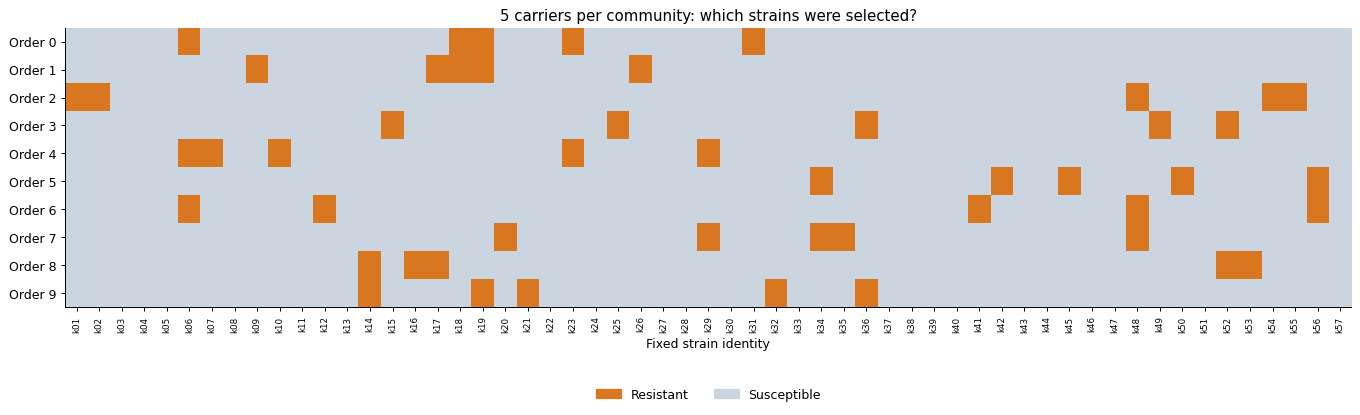

**What these results show:** All 10 rows contain exactly 5 carriers. Carrier identities change, but intrinsic traits and the initial total 0.005 OD do not.

In [9]:
plot_assignment_map()

## 2. Biomass and composition over time

**Calculation:** total height is $B(t)=\sum _iN_i(t)$. Each colored band has vertical thickness $N_i(t)$; its share of the height is $p_i(t)=N_i(t)/B(t)$. The integrated area of a band is not a relative abundance.

**Read it:** each row is one carrier count; left is untreated and right is treated. All panels use the same scale and strain colors. Black traces total biomass. The small initial inoculum is intentional. The sharp 24 h drop is the imposed dilution, not direct antibiotic killing.

**Purpose:** distinguish “the community became large again” from “the original strains returned in the same proportions.” The color key is a legend, not a separate biological measurement.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

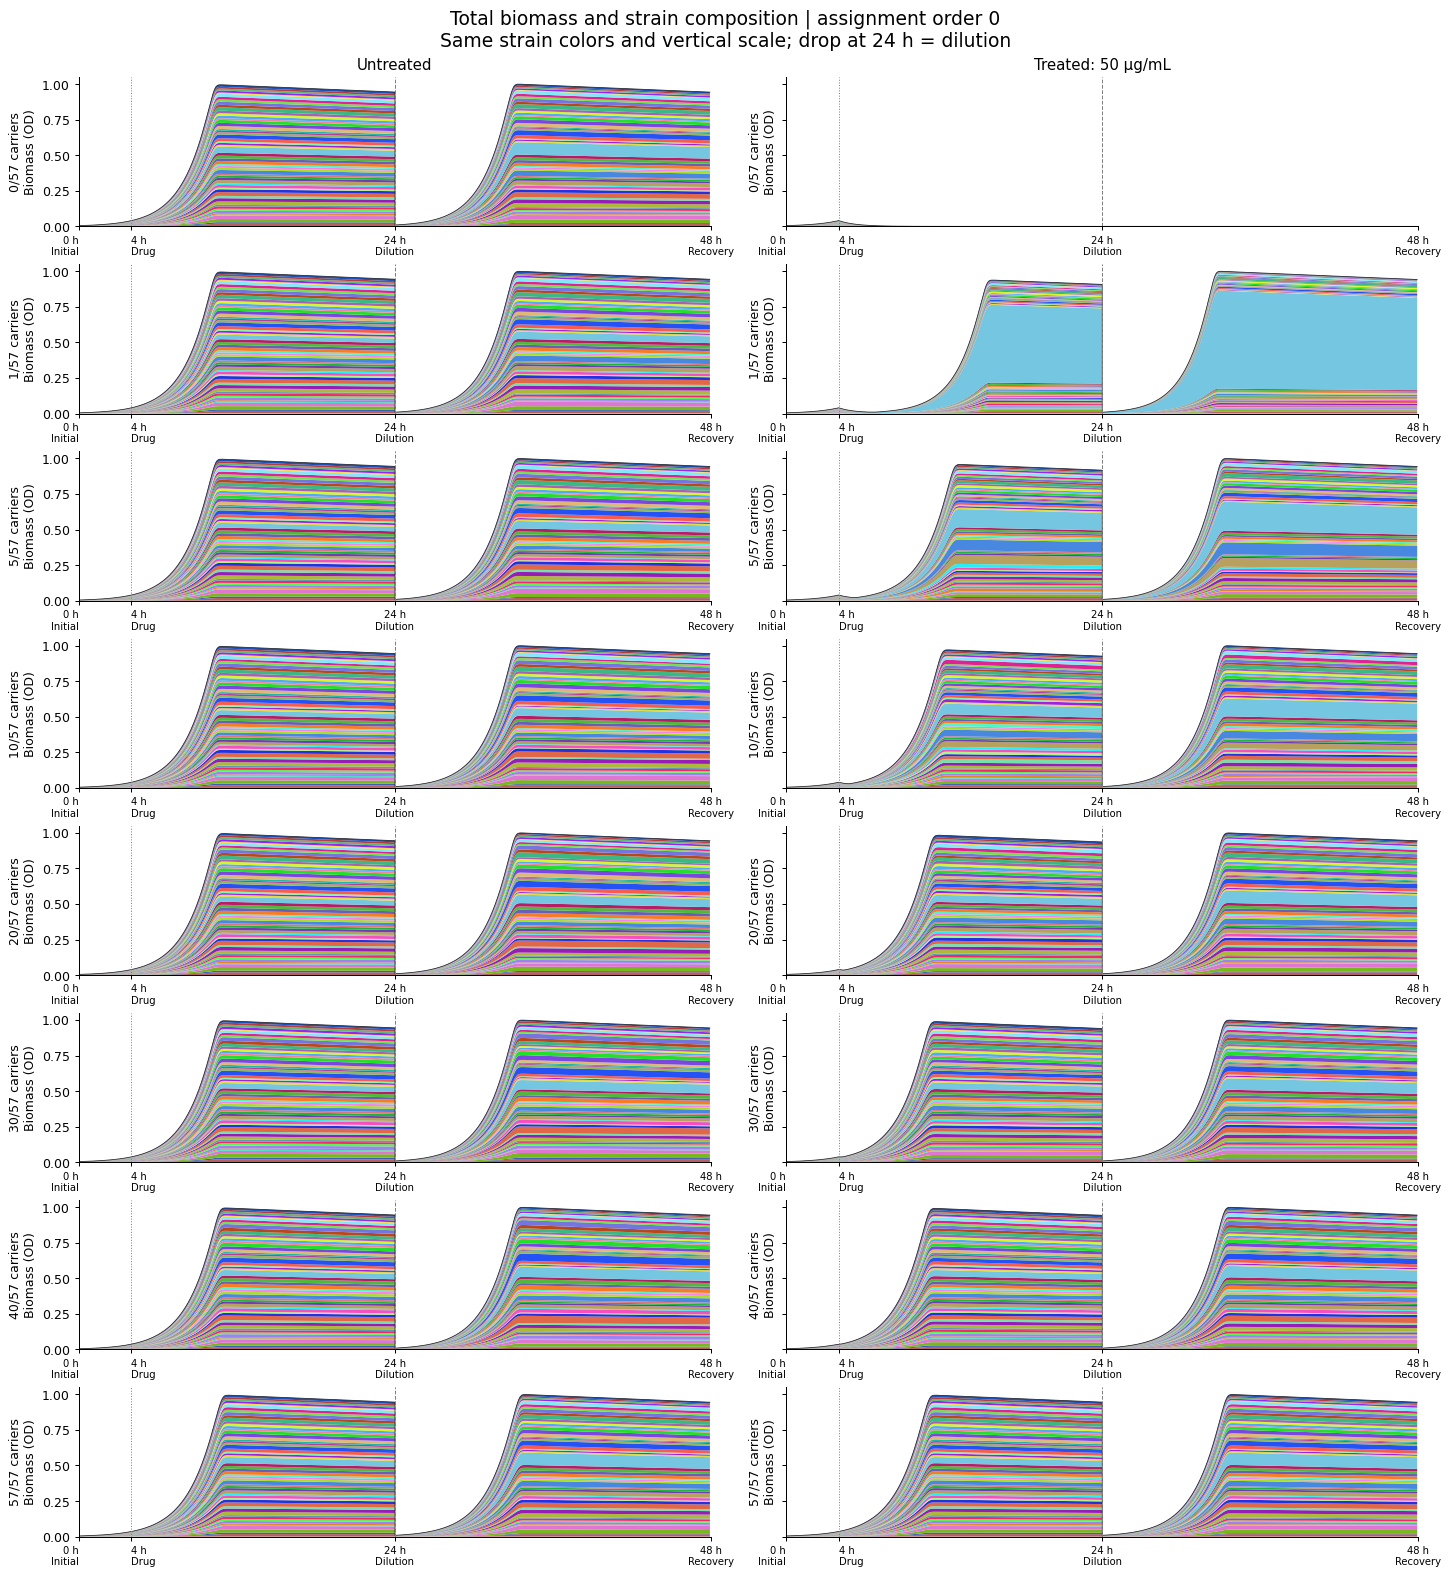

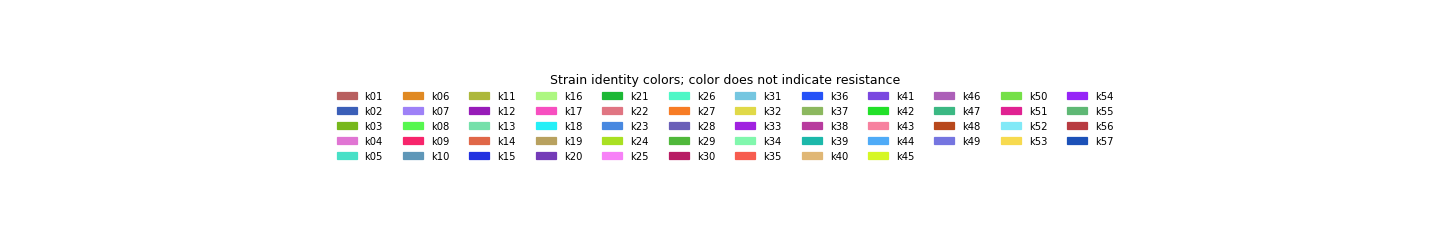

**What these results show:** At the nominal 48 h endpoint, 1/62 treated configurations are extinct. Surviving communities have 0.942–0.945 OD. Similar total biomass does not imply the same strain composition.

In [10]:
plot_absolute_trajectories()

## 3. Same carrier count, different carrier identities

**Calculation:** each curve uses actual total biomass $B$, Shannon $H=-\sum  p_i\ln  p_i$, or Gini–Simpson $S=1-\sum  p_i^2$ at each recorded time. No averaging is done in this figure.

**Read it:** one colored line is one assignment order at the selected carrier count. Colors remain consistent in later assignment plots. Higher H/S means greater diversity; higher biomass means a larger community. Carrier sets can give different deterministic curves even though all communities contain the same number of resistant strains.

**Purpose:** assess the importance of *which strains* are resistant. These are not stochastic replicates, so their separation must not be attributed to Gillespie noise.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

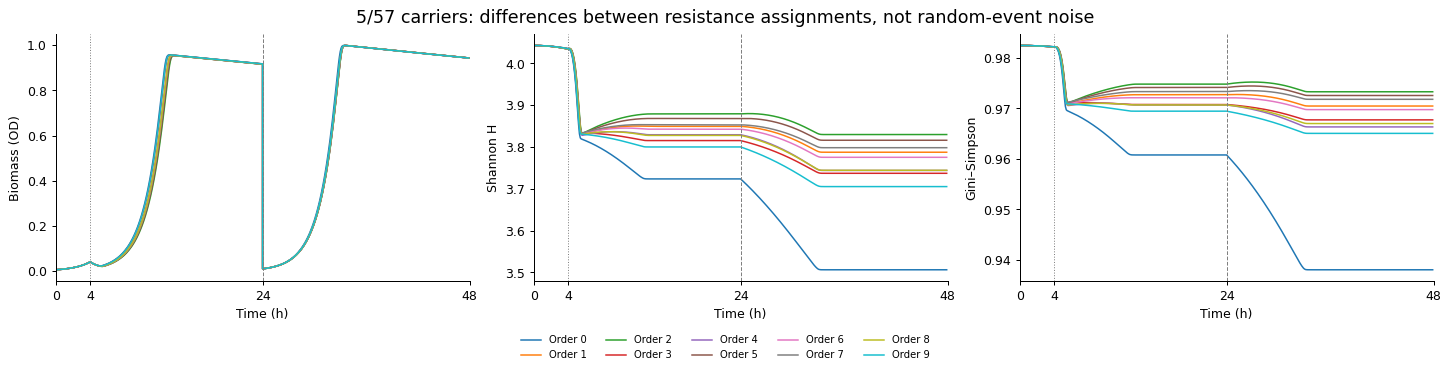

**What these results show:** At 48 h, Shannon ranges from 3.506 to 3.830 even though every displayed community has the same carrier count. The different carrier identities are sufficient to change the deterministic outcome.

In [11]:
plot_assignment_timecourses()

## 4. Diversity and restructuring heatmaps

**Calculation:** each square is one order/count/time combination, using $H=-\sum  p_i\ln  p_i$, $S=1-\sum  p_i^2$, or $BC=\frac12\sum \lvert p_i(t)-p_i(4)\rvert $.

**Read it:** columns are carrier counts, rows are assignment orders, and the three time columns are 6, 24 and 48 h. A metric uses the same color scale at all three times. Shannon/Simpson use higher = more diverse. Bray–Curtis uses lower = closer to pretreatment composition; its palette is reversed so brighter cells still indicate greater preservation. Numeric labels are the actual values. Gray means undefined, not zero change.

**Purpose:** read across a row for carrier-count effects and down a column for carrier-identity effects. Shannon's maximum here is about 4.04; Gini–Simpson's is about 0.982. The zero/all-carrier references have no order variation and are shown once in the table.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

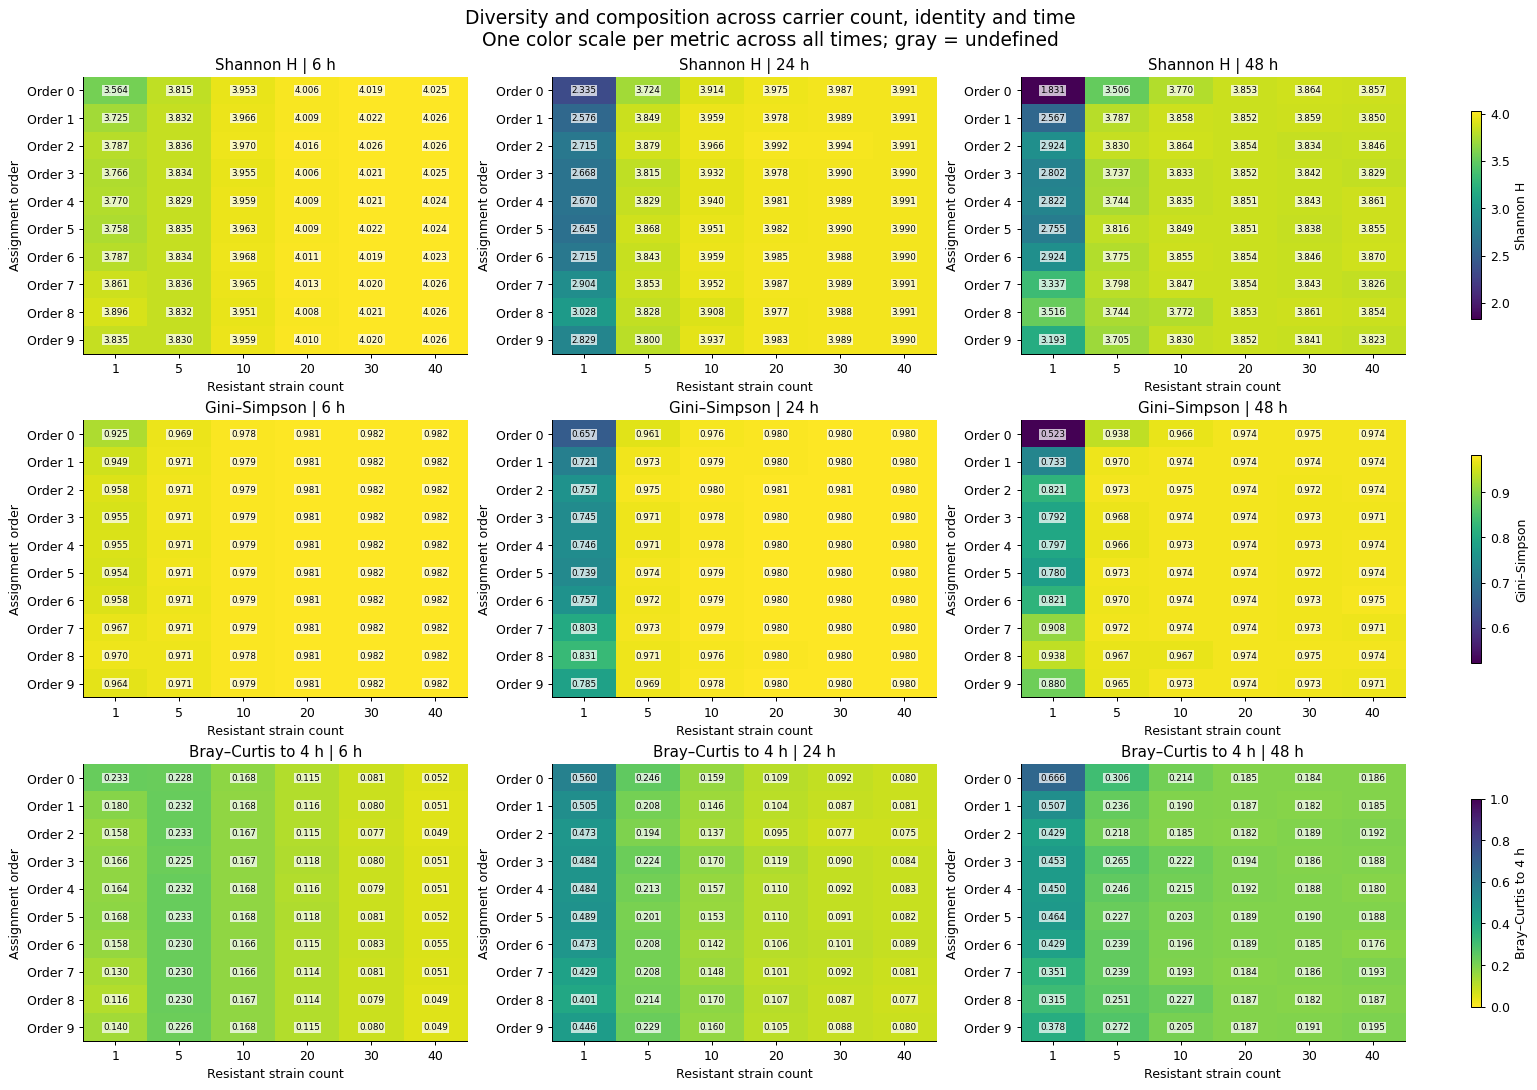

,n_resistant,hour,biomass,shannon,simpson,bray_curtis
607,0,6.0,0.0085,4.0421,0.9824,0.0390
608,0,24.0,0.0000,NaN,NaN,NaN
609,0,48.0,0.0000,NaN,NaN,NaN
617,57,6.0,0.0984,4.0266,0.9819,0.0241
618,57,24.0,0.9454,3.9907,0.9805,0.0791
619,57,48.0,0.9447,3.8533,0.9737,0.1870


**What these results show:** At 48 h, median Shannon is 2.873–3.853 across intermediate carrier counts. The 0/57 and 57/57 references are listed once below the heatmap because they have no alternative identity assignments.

In [12]:
plot_metric_heatmaps()

## 5. Resistant versus susceptible biomass: the average trend

**Calculation:** in each configuration, $B_R=\sum _{carrier}N_i$, $B_S=\sum _{susceptible}N_i$ and $f_R=B_R/(B_R+B_S)$. Absolute bars average $B_R$ and $B_S$ across assignments. Percentage bars average the *individual fractions*: $\bar f_R=\frac1m\sum _jf_{R,j}$. This differs from pooling biomass, which would give bigger communities more weight.

For a quantity $z$, the black standard-deviation bar is $s=\sqrt{\sum _j(z_j-\bar z)^2/(m-1)}$. It describes identity variation, not confidence or random-event noise. On the absolute panel it refers to total biomass; on the percentage panel it refers to resistant share.

**Read it:** within each pair, hatched left = 4 h baseline, solid right = 48 h recovery. Orange = resistant; gray = susceptible. Endpoint labels give resistant percentage. References are counted once and have no assignment SD.

**Purpose:** a resistant percentage can increase because resistant biomass grows, susceptible biomass falls, or both. Compare both panels. Extinct communities count as zero biomass but have undefined percentages; percentage means therefore describe nonempty communities, with `n_nonempty` reported.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

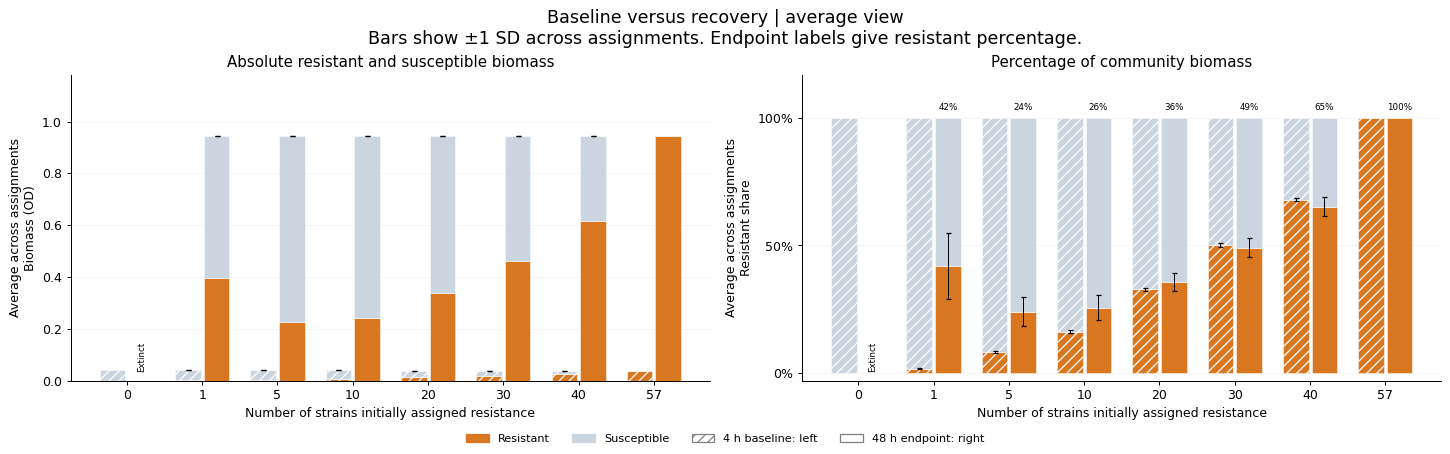

,n_resistant,hour,resistant_share,biomass,n,n_nonempty
0,0,4.0,0.0000,0.0404,1,1
1,0,48.0,NaN,0.0000,1,0
2,1,4.0,0.0164,0.0403,10,10
3,1,48.0,0.4194,0.9439,10,10
4,5,4.0,0.0804,0.0401,10,10
5,5,48.0,0.2401,0.9436,10,10
6,10,4.0,0.1613,0.0397,10,10
7,10,48.0,0.2553,0.9436,10,10
8,20,4.0,0.3286,0.0390,10,10
9,20,48.0,0.3575,0.9438,10,10


**What these results show:** For 1 initial carrier(s), average resistant share changes from 1.6% at baseline to 41.9% at recovery. A larger percentage does not, by itself, establish absolute resistant growth.

In [13]:
plot_resistance_bars(mode='average')

## 6. Does baseline resistant percentage predict endpoint resilience?

**Calculation:** x is $x=100B_R(4)/B(4)$. Y is Shannon retention $H(48)/H(4)$, Simpson retention $S(48)/S(4)$ or baseline-relative Bray–Curtis. This x-axis is a percentage on a linear scale, not absolute biomass and not measured β-lactamase abundance.

A candidate descriptive curve is $y=c+A\exp (-x/K)$, where x and K are in percentage units. Negative A produces an increasing curve; positive A a decreasing curve. Parameters minimize $\sum _j[y_j-\hat y_j]^2$ over intermediate configurations. The plotted curve is restricted to their observed x range.

Fit quality is $R^2=1-\frac{\sum _j(y_j-\hat y_j)^2}{\sum _j(y_j-\bar y)^2}$ and $RMSE=\sqrt{\frac1n\sum _j(y_j-\hat y_j)^2}$. R² describes the fitted data; it is not percent accuracy, a p-value, or evidence of causation. This unconstrained candidate can predict impossible values outside its fitted range: do not extrapolate.

**Read it:** each dot is a configuration, colored by order. A favorable pattern would generally be higher retention and lower Bray–Curtis at greater baseline resistance. Shared references are shown but not fitted. Undefined extinction outcomes are excluded and reported separately.

**Purpose:** summarize the observed relationship without assuming that a larger resistant fraction always improves every recovery measure. A good curve does not independently validate mechanisms already built into the model.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

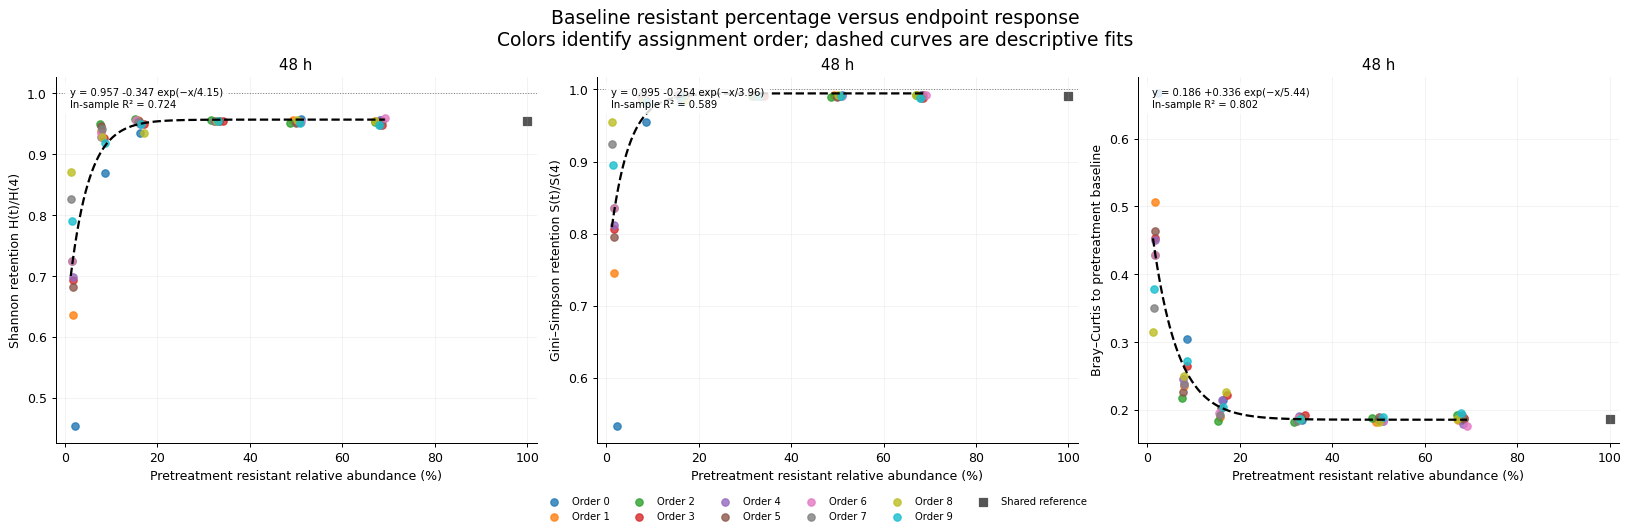

,metric,c,A,K_percent,r2,rmse
0,shannon_retention,0.95699,-0.34662,4.15016,0.72386,0.05252
1,simpson_retention,0.99452,-0.25445,3.95586,0.58940,0.05118
2,bray_curtis_to_baseline,0.18598,0.33604,5.43805,0.80170,0.04476


**What these results show:** The fitted curves summarize variation across the displayed configurations. They do not establish a mechanistic law or out-of-sample accuracy. Extinct communities have undefined diversity/composition and are listed separately in the extinction table.

In [14]:
plot_resistance_fits()

## 7. Did resistant strains become more dominant?

**Calculation:** x is $100B_R(4)/B(4)$ and y is $100B_R(48)/B(48)$. Their difference is a change in **percentage points**, not a fold change.

The black diagonal is $y=x$: a no-change reference, **not a fit**. The red quadratic is $\hat y=a+bx+cx^2$. Its coefficients minimize squared residuals over intermediate configurations; its in-sample R² uses the formula in the preceding section. The shared references are not fitted. A quadratic is a local summary and is not guaranteed to stay in 0–100% outside the observed range.

**Read it:** above the diagonal means resistant bacteria occupy a greater share after recovery; below means a smaller share. Colors show carrier orders.

**Purpose:** quantify selection toward resistance while remembering that an increased fraction does not prove increased absolute resistant biomass. Extinction gives no defined percentage and no scatter point.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

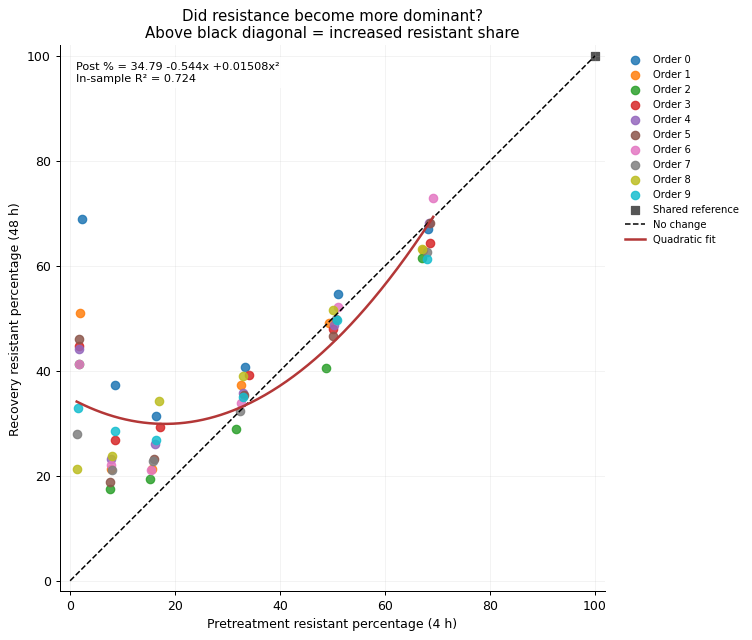

**What these results show:** 43/60 nonempty intermediate configurations increase in resistant percentage. The quadratic has R² = 0.724 on the fitted data. Neither result alone proves an increase in absolute resistant biomass.

In [15]:
plot_pre_post_resistance()

## 8. Which strains contributed most to composition change?

**Calculation:** for strain i, signed change is $\Delta  p_i=p_i(48)-p_i(4)$; its Bray–Curtis contribution is $C_i=\frac12\lvert \Delta  p_i\rvert $. Contributions sum to the whole-community distance: $\sum _iC_i=BC(48,4)$.

**Read it:** rows are the top strains ranked by mean contribution across intermediate configurations; columns are carrier counts. Left: magnitude of contribution, regardless of direction. Right: signed gain/loss in relative share. Values average over nonempty configurations at each count. Gray is undefined after extinction. References are not artificially repeated across orders.

**Purpose:** identify the strains whose abundance changes account for restructuring. This does not identify which strain *caused another strain to change*. Relative gains can result from other strains declining.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

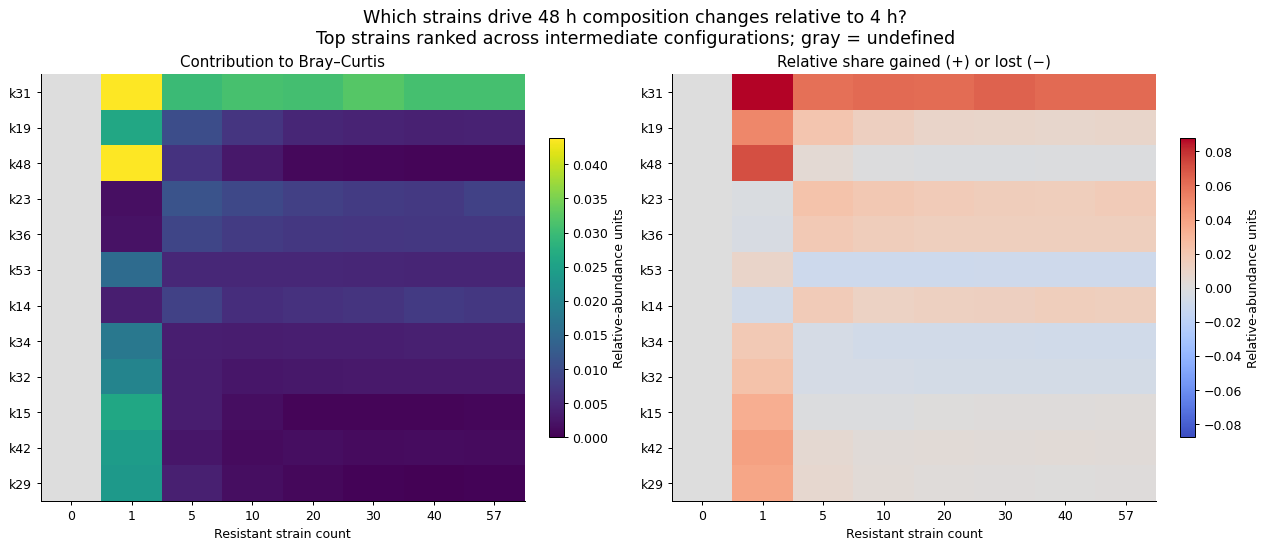

**What these results show:** k31 has the largest average contribution (0.0331 Bray–Curtis units). Contribution is a magnitude; the signed heatmap distinguishes gains from losses. These are contributors to a measured change, not proven causes of changes in other strains.

In [16]:
plot_strain_heatmaps()

## 9. Ranking restructuring magnitude versus direction

**Calculation:** average each strain's $C_i=\frac12\lvert \Delta  p_i\rvert $ across the intermediate configurations to rank it. Average signed change separately; multiply $\overline{\Delta  p_i}$ by 100 to express percentage points.

**Read it:** left bars show who contributes most to Bray–Curtis; right bars distinguish relative winners and losers. A large contribution can come from a large loss, not just dominance. Averaging signed changes can cancel gains and losses across different configurations; average absolute contribution does not cancel.

**Purpose:** provide a compact ranking and an exact trait/response table for the leading strains. This ranking is descriptive rather than a multiple-testing significance result.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

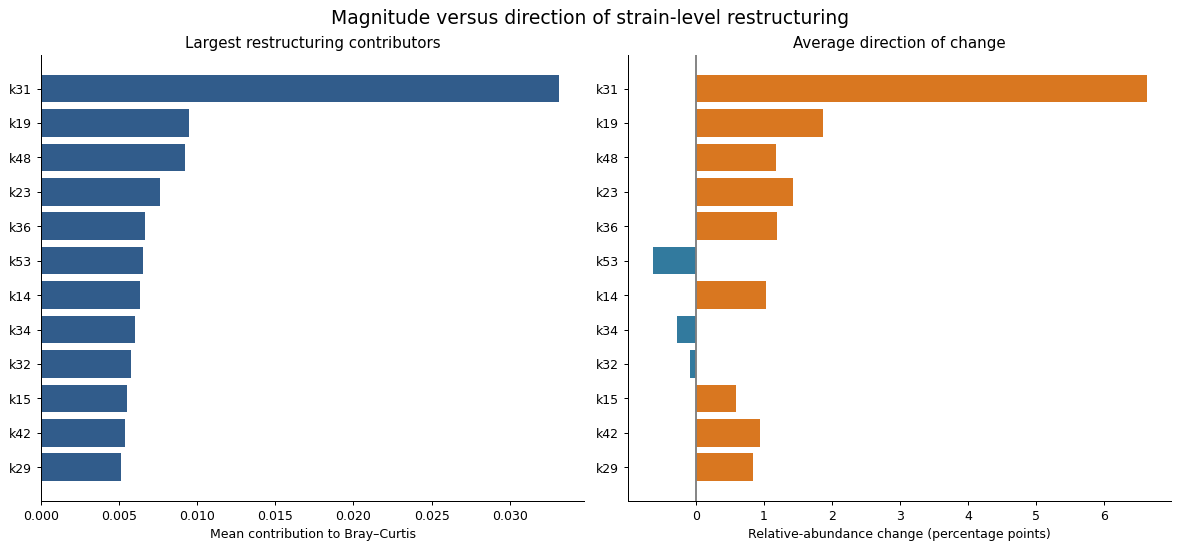

,mean_BC_contribution,mean_relative_shift,mean_adjusted_shift,mean_excess_contribution,intrinsic_growth,ic50,carrier_frequency
strain,,,,,,,
k31,0.03312,0.06624,0.00317,0.00159,0.65053,3.94790,0.28333
k19,0.00946,0.01862,0.01158,0.00589,0.58810,6.34570,0.43333
k48,0.00923,0.01175,0.01330,0.00790,0.55813,2.03583,0.38333
k23,0.00762,0.01426,0.00025,0.00062,0.60448,3.15155,0.46667
k36,0.00664,0.01193,-0.00128,0.00004,0.59998,2.90993,0.38333
k53,0.00651,-0.00635,0.00257,0.00205,0.48801,1.16802,0.20000
k14,0.00633,0.01025,-0.00454,-0.00107,0.59990,1.60233,0.28333
k34,0.00601,-0.00281,0.00505,0.00208,0.51375,6.23518,0.43333
k32,0.00577,-0.00082,0.00523,0.00274,0.53074,5.47921,0.35000


**What these results show:** The ranking averages across the six intermediate carrier counts and their assignment orders. Positive signed change means a larger relative share; it can occur even if absolute biomass did not increase.

In [17]:
plot_strain_ranking()

## 10. How do those strains compare in growth speed and resistance?

**Calculation:** intrinsic growth is the strain's fixed maximum $\mu _i^{\mathrm{intrinsic}}$. A carrier's effective maximum is $\mu _i=\mu _i^{\mathrm{intrinsic}}(1-c)$; a susceptible strain retains its intrinsic maximum. Growth rank 1 is fastest among all 57 strains. The left plotted quantity is $100[\mu _i/\overline{\mu ^{\mathrm{intrinsic}}}-1]$. Zero is the community's mean intrinsic maximum; it is not no growth.

The right quantity is $100 \overline{p_i(48)-p_i(4)}$, computed separately for configurations where that strain was resistant or susceptible.

**Read it:** blue = susceptible observations; orange = resistant observations. Positive left values mean faster than the community reference; positive right values mean increased community share. Realized growth can still be slow when nutrients are scarce, even for a high maximum growth rate.

**Purpose:** connect the major restructuring contributors to fixed growth traits and changing carrier status. A strain is not permanently resistant across all trials. These averages combine carrier counts, so a resistant/susceptible difference is not an isolated causal resistance effect. The table includes observation counts and underlying IC50; IC50 affects killing only when the strain is susceptible, because carriers are modeled as immune.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

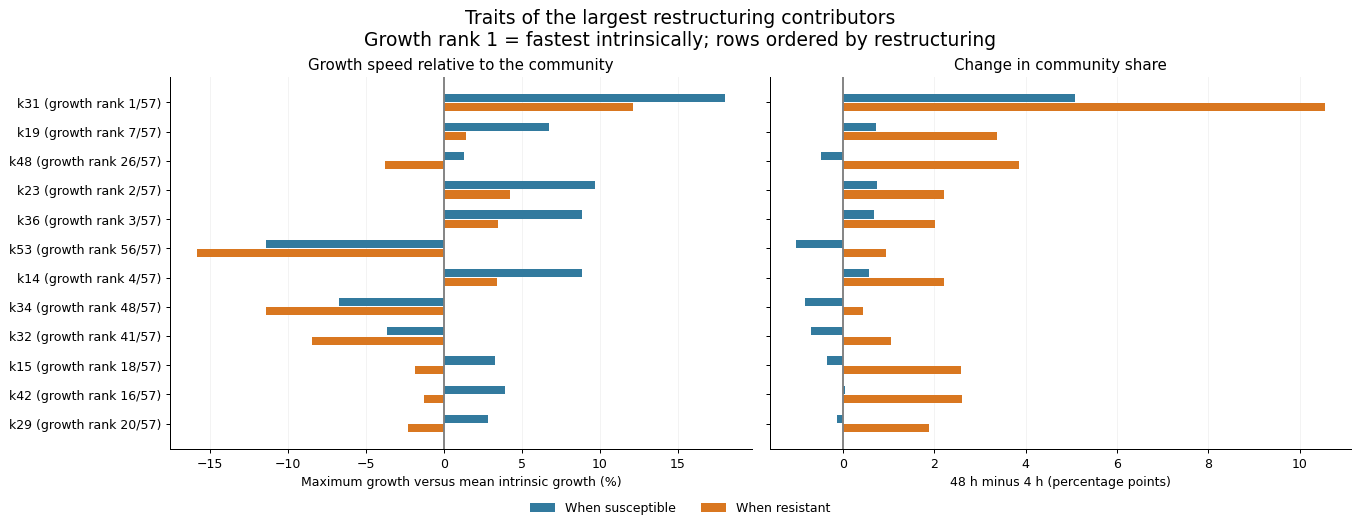

**What these results show:** k31, the largest average contributor, has intrinsic growth rank 1/57 and grows +18.1% relative to the community mean before resistance cost. The carrier penalty lowers maximum growth by 5%. Status-specific abundance averages combine carrier counts and are descriptive, not isolated resistance effects.

,strain,carrier,n_configurations,effective_growth,mean_BC_contribution,mean_baseline_share,mean_endpoint_share,mean_relative_shift,intrinsic_growth,growth_rank,growth_vs_average_percent,status,change_percentage_points
26,k14,False,43,0.5999,0.0045,0.0215,0.0271,0.0056,0.5999,4,8.8675,Susceptible,0.5581
27,k14,True,17,0.5699,0.0110,0.0196,0.0417,0.0221,0.5999,4,8.8675,Resistant,2.2056
28,k15,False,41,0.5691,0.0020,0.0191,0.0156,-0.0035,0.5691,18,3.2793,Susceptible,-0.3454
29,k15,True,19,0.5407,0.0129,0.0176,0.0435,0.0259,0.5691,18,3.2793,Resistant,2.5878
36,k19,False,34,0.5881,0.0038,0.0205,0.0276,0.0071,0.5881,7,6.7255,Susceptible,0.7108
37,k19,True,26,0.5587,0.0168,0.0187,0.0524,0.0337,0.5881,7,6.7255,Resistant,3.3685
44,k23,False,32,0.6045,0.0046,0.0217,0.0291,0.0074,0.6045,2,9.6993,Susceptible,0.7399
45,k23,True,28,0.5743,0.0110,0.0200,0.0421,0.0221,0.6045,2,9.6993,Resistant,2.2096
56,k29,False,31,0.5666,0.0011,0.0188,0.0175,-0.0013,0.5666,20,2.8284,Susceptible,-0.1306
57,k29,True,29,0.5383,0.0094,0.0174,0.0362,0.0188,0.5666,20,2.8284,Resistant,1.8819


In [18]:
plot_strain_traits()

## 11. Compare the same strain at a fixed carrier count

**Calculation:** first compute untreated-adjusted change $D_i=[p_{i,T}(48)-p_{i,T}(4)]-[p_{i,C}(48)-p_{i,C}(4)]$. At the fixed count of 20 carriers, compare the same strain's averages when resistant and susceptible: $100[\overline{D_i\mid  R}-\overline{D_i\mid  S}]$.

**Read it:** positive bars mean a greater adjusted relative gain when the strain was resistant. At least two configurations in each status are required. Strains are displayed by the largest absolute contrast, not by a significance threshold. Counts are available in the table.

**Purpose:** control the total carrier count and intrinsic strain identity more carefully than the pooled profiles. Other carriers still vary between assignment orders, so this is an association within the selected design. A one-strain causal test would switch only that strain while holding all other assignments fixed.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

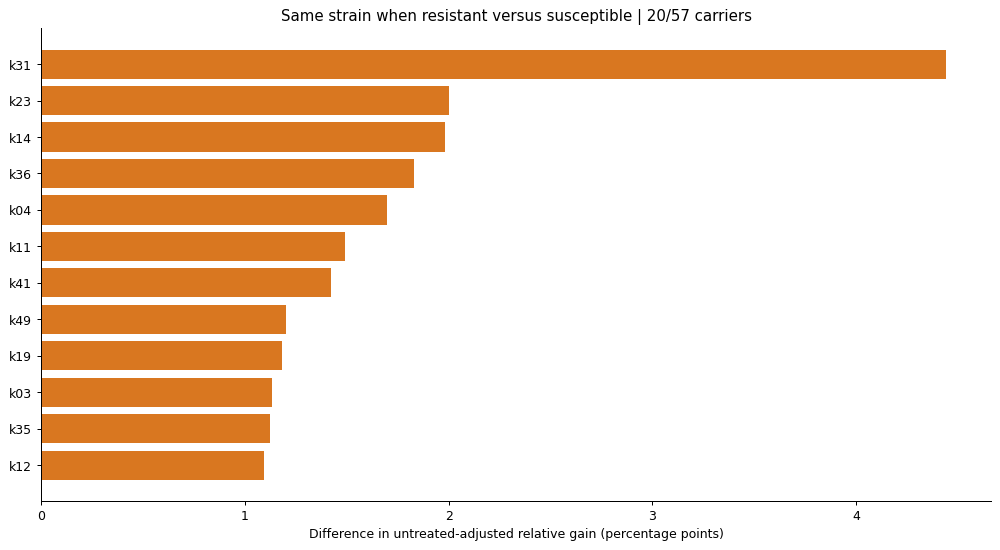

,mean_adjusted_shift_S,mean_adjusted_shift_R,n_S,n_R,R_minus_S
strain,,,,,
k31,-0.01563,0.02878,7.0,3.0,0.04441
k23,-0.00755,0.01249,6.0,4.0,0.02004
k14,-0.00859,0.01126,7.0,3.0,0.01984
k36,-0.00700,0.01129,5.0,5.0,0.01829
k04,-0.00765,0.00931,6.0,4.0,0.01696
k11,-0.00573,0.00918,5.0,5.0,0.01491
k41,-0.00591,0.00831,6.0,4.0,0.01423
k49,-0.00441,0.00761,7.0,3.0,0.01202
k19,-0.00307,0.00877,6.0,4.0,0.01183


**What these results show:** 50 strains have at least 2 resistant and 2 susceptible observations at this count. The largest absolute contrast is 4.44 percentage points. Other carriers also differ between orders, so this is not a one-strain causal intervention.

In [19]:
plot_fixed_count_status()

## 12. Different measures of recovery over time

**Calculation:** for each carrier count and time, compute the median, minimum and maximum across assignment orders for Shannon retention, Bray–Curtis, treated/untreated biomass ratio and resistant biomass share. These summaries operate on each community's metric, not on an averaged strain profile.

**Read it:** each line is a carrier count; shading is the observed min–max range across identities, **not a confidence interval**. The horizontal references are 1 for retention or biomass ratio and 0 for Bray–Curtis. A resistant share near 1 indicates dominance, not necessarily community protection.

**Purpose:** see whether community size, diversity, composition and resistance dominance tell the same story, and whether the relationship changes during recovery.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

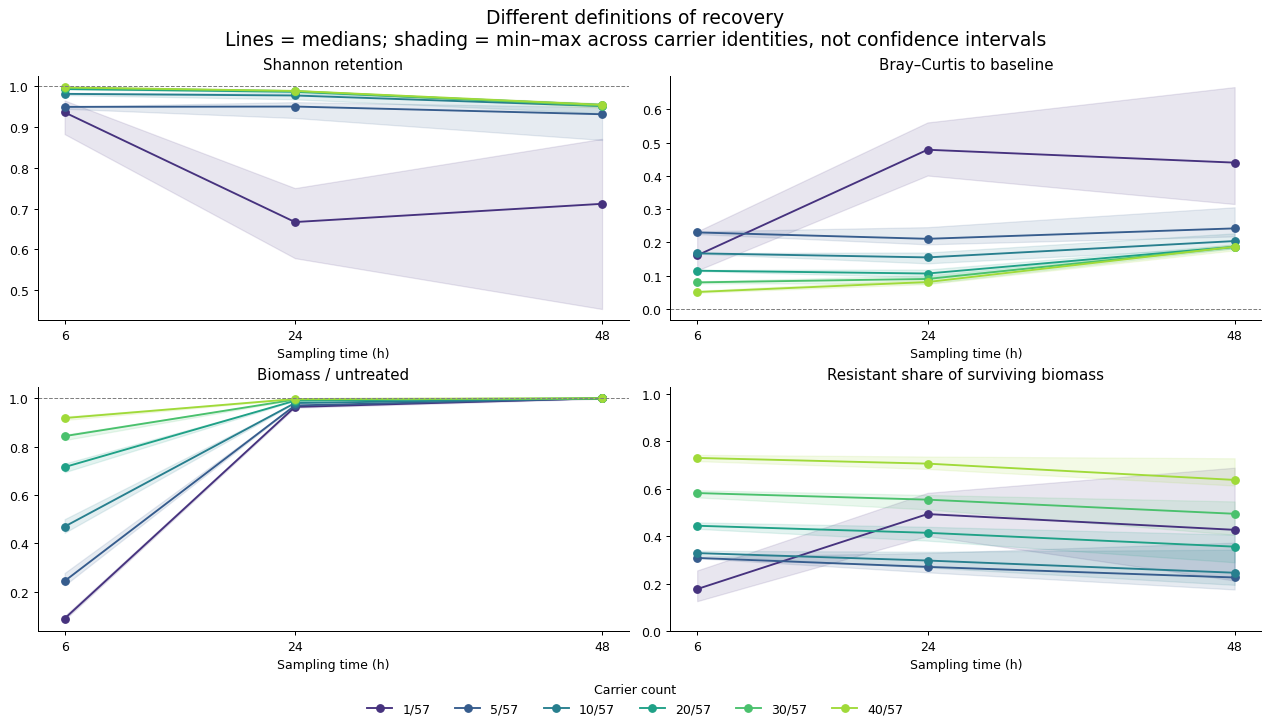

**What these results show:** At recovery, biomass/untreated ranges from 0.998 to 1.002, while baseline-relative Bray–Curtis ranges from 0.176 to 0.666. Recovering community size and recovering its original composition are different outcomes.

In [20]:
plot_outcome_summary()

# Supplementary views and interpretation checks

The next sections retain the uploaded notebook's absolute-biomass correlation analysis, untreated adjustments, bootstrap uncertainty and detailed assignment bar plots. They answer related questions without mixing absolute abundance with percentages.


## S1. Absolute baseline resistant biomass versus response

**Calculation:** x is $B_R(4)=\sum _{carrier}N_i(4)$ in OD, not a fraction. Y is retention or baseline-relative Bray–Curtis. Spearman $\rho $ is the Pearson correlation of the ranks of x and y: it measures monotonic association on a scale of −1 to +1. Only intermediate configurations with defined outcomes enter it.

The dashed guide is $\hat y=a+b\log _{10}(x)$, fit by least squares over positive intermediate points. The axis is **symlog**: linear near zero to retain the reference, logarithmic above the displayed transition. No pseudocount is added. The zero/all references are plotted but not fitted.

**Read it:** positive retention ρ or negative Bray–Curtis ρ is consistent with greater preservation at higher baseline carrier biomass. Equal logarithmic spacing means equal fold changes, not equal OD increments.

**Purpose:** distinguish absolute enzyme-capacity proxy from relative resistant abundance. Because each carrier has the same capacity per OD, multiplying x by `vmax` only rescales it; it does not turn it into measured enzyme abundance.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

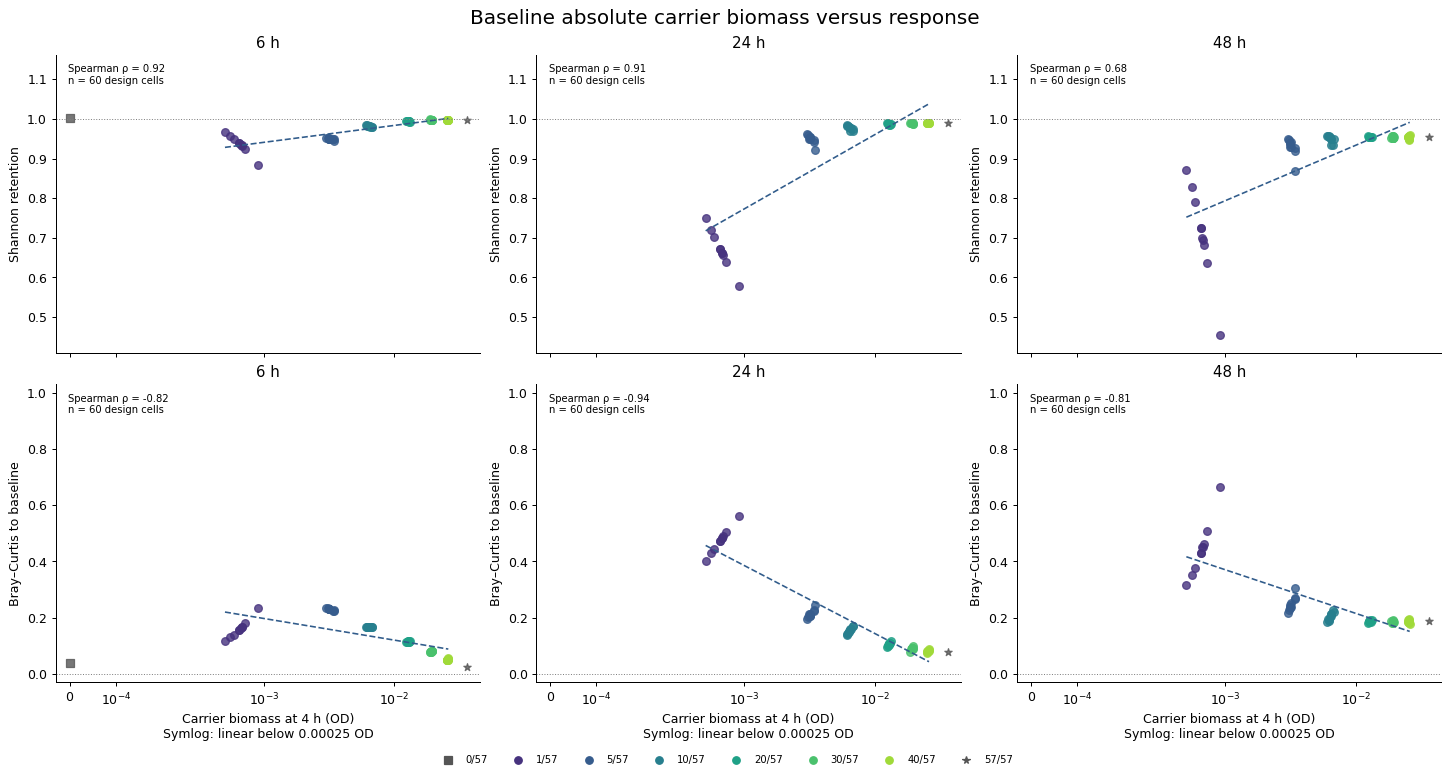

,metric,hour,n,distinct_masks,orders,rho,low,high,pearson_r_log10_x
0,shannon_retention,6.0,60,59,10,0.916,0.903,0.939,0.888
1,shannon_retention,24.0,60,59,10,0.909,0.864,0.952,0.868
2,shannon_retention,48.0,60,59,10,0.682,0.561,0.805,0.757
3,bray_curtis_to_baseline,6.0,60,59,10,-0.819,-0.862,-0.789,-0.686
4,bray_curtis_to_baseline,24.0,60,59,10,-0.937,-0.954,-0.926,-0.950
5,bray_curtis_to_baseline,48.0,60,59,10,-0.808,-0.905,-0.699,-0.835


**What these results show:** The x-axis measures absolute carrier biomass, not its percentage. Reported correlations apply to intermediate configurations; the endpoint references are not fitted. Shared axes show how the relationship changes over time without silently changing each panel’s scale.

In [21]:
plot_absolute_correlations(adjusted=False)

## S2. Do associations remain after untreated comparison?

**Calculation:** adjusted Shannon is $[H_T(t)/H_T(4)]/[H_C(t)/H_C(4)]$. A value of 1 means the same retention as the matched untreated community. Excess Bray–Curtis is $BC_T(t,4)-BC_C(t,4)$; zero means equal displacement magnitudes from each arm's own baseline. Each arm normalizes its own strain abundances before calculating distances.

**Read it:** excess Bray–Curtis can be negative if the treated community is less displaced from baseline than the untreated one. It compares magnitudes, not compositional vectors. It is not direct treated-versus-control dissimilarity. X, color and fit conventions match S1.

**Purpose:** assess whether competition, growth costs and dilution alone can explain changes. This is a matched model comparison, not proof of the mechanism in real communities.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

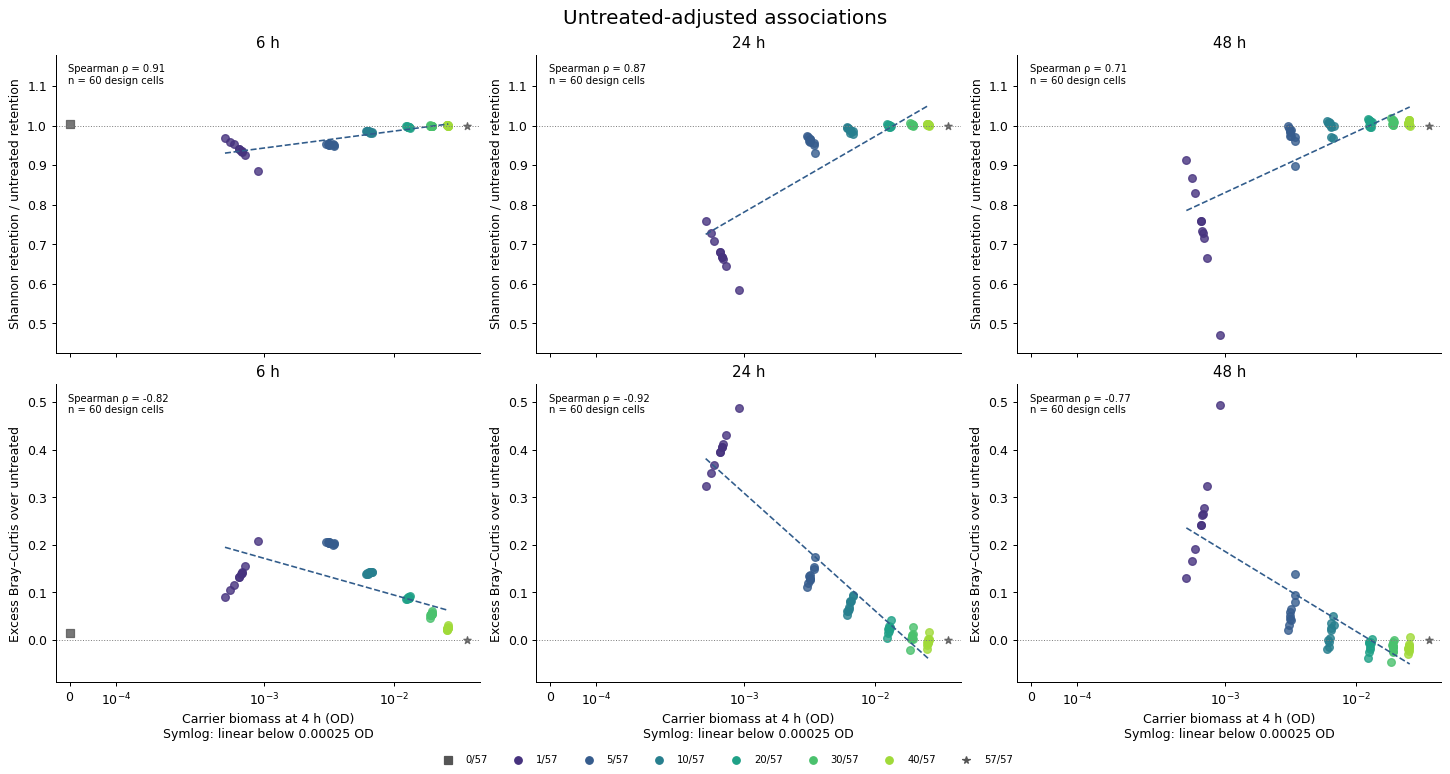

,metric,hour,n,distinct_masks,orders,rho,low,high,pearson_r_log10_x
6,adjusted_shannon_retention,6.0,60,59,10,0.906,0.887,0.934,0.888
7,adjusted_shannon_retention,24.0,60,59,10,0.874,0.831,0.932,0.869
8,adjusted_shannon_retention,48.0,60,59,10,0.712,0.621,0.833,0.769
9,excess_bray_curtis,6.0,60,59,10,-0.821,-0.860,-0.795,-0.688
10,excess_bray_curtis,24.0,60,59,10,-0.921,-0.956,-0.892,-0.950
11,excess_bray_curtis,48.0,60,59,10,-0.770,-0.864,-0.696,-0.845


**What these results show:** The x-axis measures absolute carrier biomass, not its percentage. Reported correlations apply to intermediate configurations; the endpoint references are not fitted. Shared axes show how the relationship changes over time without silently changing each panel’s scale.

In [22]:
plot_absolute_correlations(adjusted=True)

## S3. Correlation strength and uncertainty over time

**Calculation:** compute pooled Spearman ρ for each metric at each time. Then draw 10 assignment-order IDs with replacement, retain all carrier counts in each selected order, recalculate ρ, and repeat 1,000 times. The 2.5th and 97.5th percentiles are an exploratory 95% **assignment-order bootstrap interval**.

The saved table also retains Pearson r for log10(x). For u = log10(x), this is r = Σ[(u − mean(u))(y − mean(y))] / √[Σ(u − mean(u))² × Σ(y − mean(y))²], a straight-line association on the transformed axis. It is secondary to the rank-based result.

**Read it:** blue points are pooled estimates; vertical blue bars are bootstrap intervals; gray dots are individual-order correlations. A correlation of zero means no monotonic association, not no biological effect. Nested carrier counts are not treated as independent points for ordinary p-values. Time points are separate views of the same communities, not additional independent replicates.

**Purpose:** evaluate identity sensitivity conditional on this one community and count grid. The interval does not capture different intrinsic communities, model parameters, mechanisms, measurement error or real microbiome sampling. Diversity correlations exclude extinct communities; extinction must be read separately.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

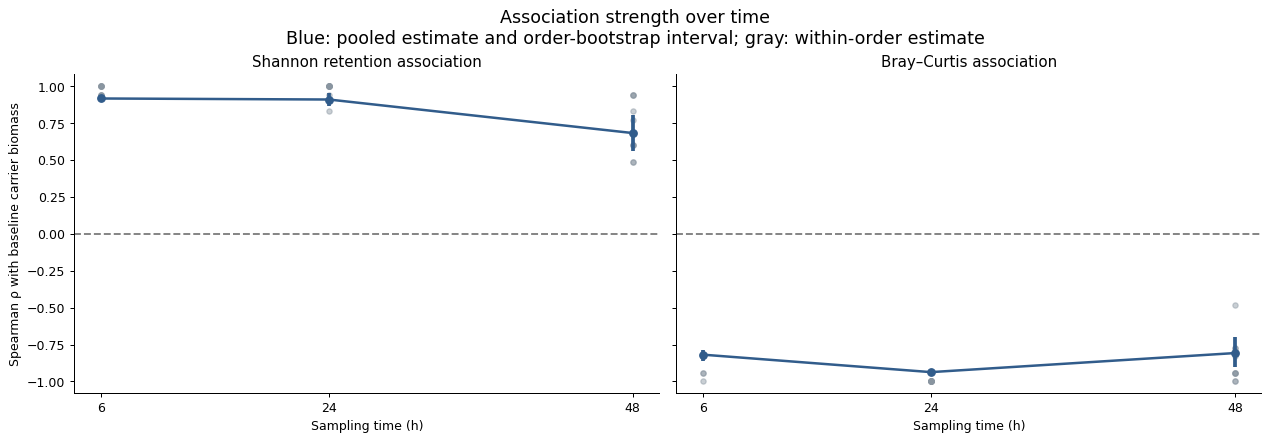

**What these results show:** At 48 h, shannon retention has ρ = 0.682, with assignment-order bootstrap interval [0.561, 0.805]. This uncertainty is conditional on this synthetic community and count grid, not natural microbiome variability.

**What these results show:** At 48 h, bray curtis to baseline has ρ = -0.808, with assignment-order bootstrap interval [-0.905, -0.699]. This uncertainty is conditional on this synthetic community and count grid, not natural microbiome variability.

In [23]:
plot_correlation_time()

## S4. Baseline versus endpoint for every assignment

**Calculation and colors:** identical to Section 5: actual $B_R$, $B_S$ and $B_R/B$ are plotted for each assignment rather than averaged.

**Read it:** each row is an order. Left panels use a shared absolute-biomass scale; right panels use fractions. Hatched left bars are baseline; solid right bars are endpoint. Endpoint labels show resistant share. The 0- and 57-carrier references repeat for visual comparison only.

**Purpose:** inspect whether the average trend hides an unusual identity assignment. These rows are deterministic configurations, not stochastic replicates.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

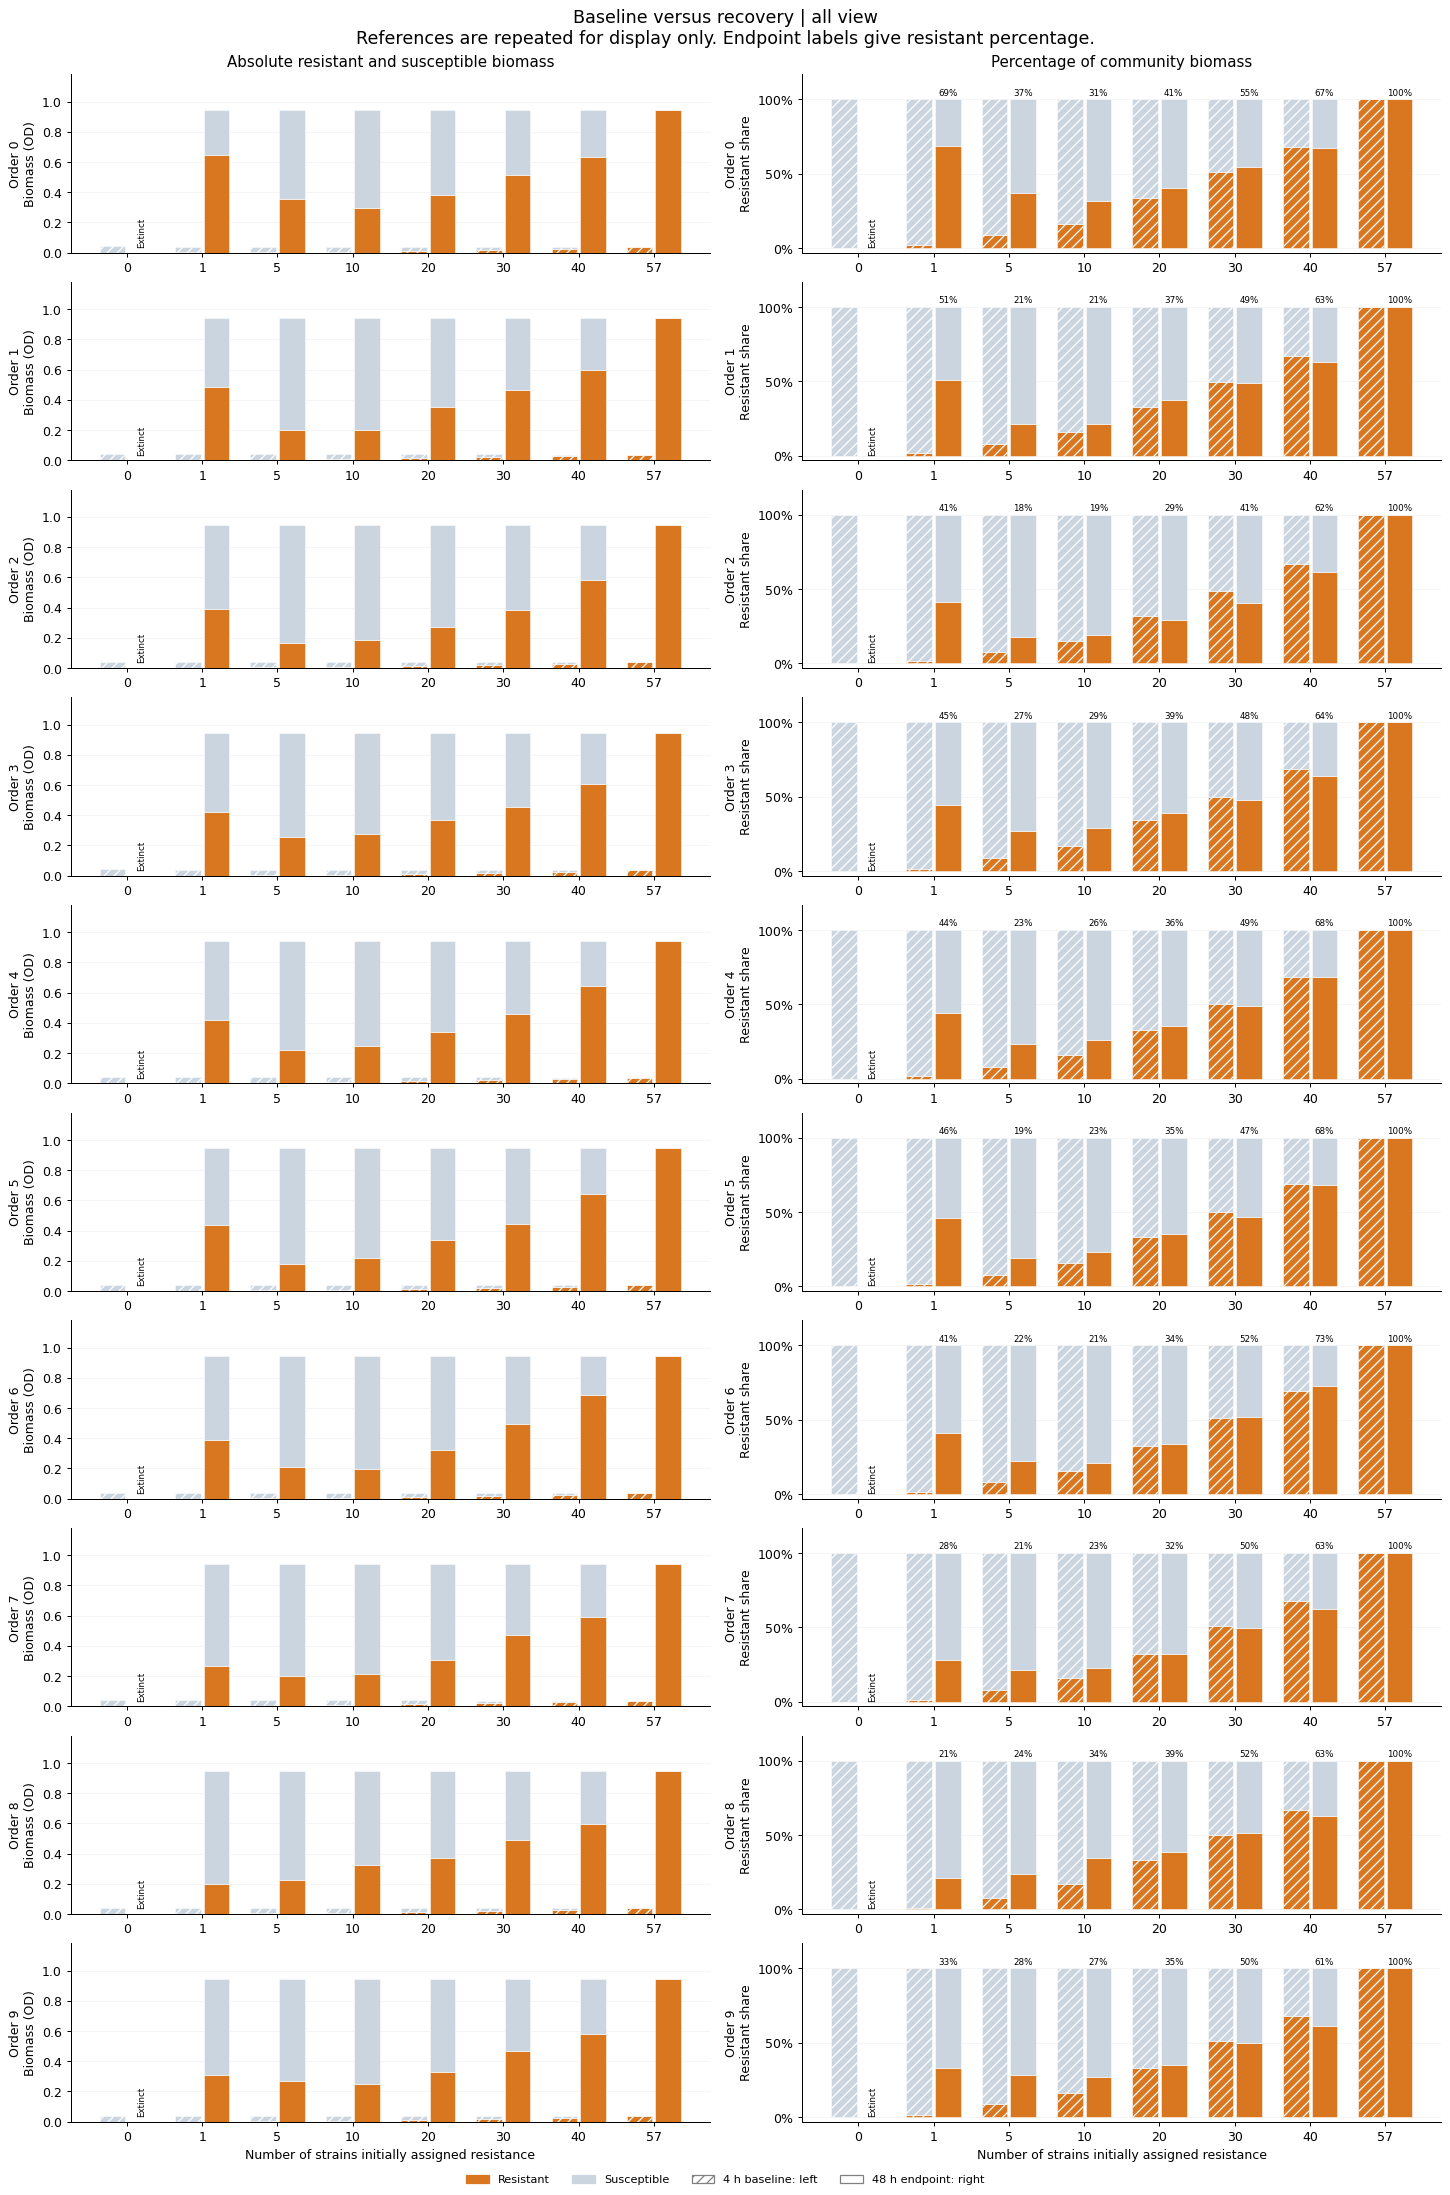

**What these results show:** Compare rows at the same carrier count to see identity effects. Compare absolute height with resistant percentage to distinguish community size from composition. The 0/57 and 57/57 displays repeat the same reference data, not extra independent trials.

In [24]:
plot_resistance_bars(mode='all')

## S5. A closer look at one assignment

**Calculation:** the same resistant/susceptible absolute and percentage calculations from Section 5, restricted to the selected order. No averaging and no variability bars are appropriate within one deterministic assignment.

**Read it:** each carrier count has a baseline/endpoint pair. Compare absolute height and relative share together. Extinction has zero biomass but undefined composition.

**Purpose:** provide a larger, easier-to-read version of one row from S4. Change `DISPLAY_ORDER` in the settings cell and rerun to choose another order.

The plotting cell below uses the shared tables. A short, data-based interpretation follows the figure.

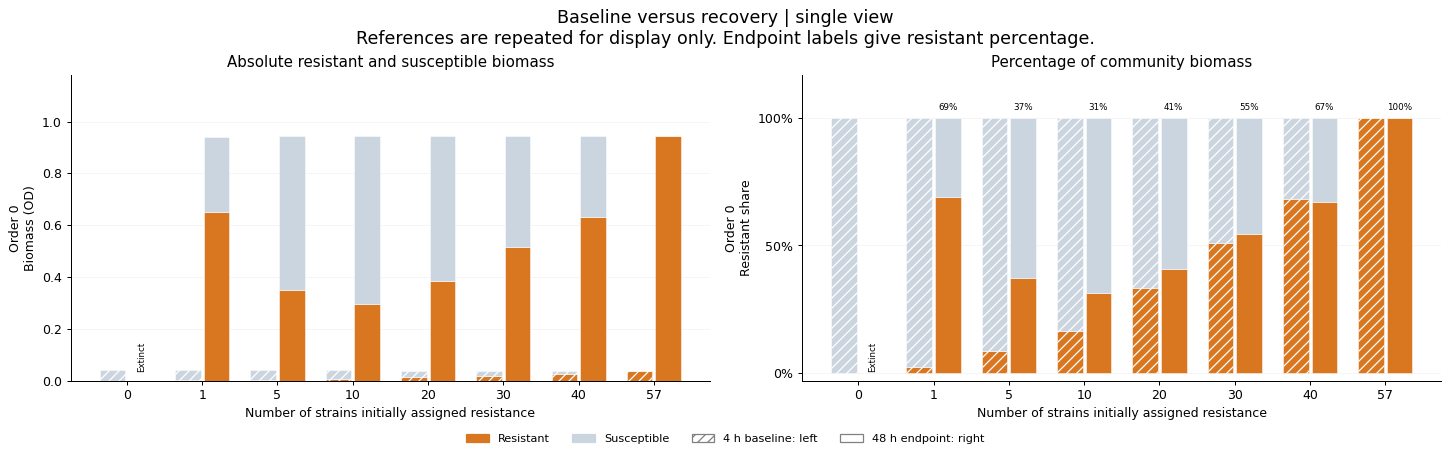

**What these results show:** Compare rows at the same carrier count to see identity effects. Compare absolute height with resistant percentage to distinguish community size from composition. The 0/57 and 57/57 displays repeat the same reference data, not extra independent trials.

In [25]:
plot_resistance_bars(mode='single', order_id=DISPLAY_ORDER)

## Final checks and a short results audit

The checks below verify that the reorganization has not changed the simulated experiment: initialization is fixed; carrier masks and effective traits match the design; the strain contributions sum to community Bray–Curtis; and extinct communities are not assigned false diversity/composition values.

The reference table is important. Early relative-composition stability can coexist with severe biomass loss, and endpoint correlations among nonempty communities do not fully describe extinction. The computed note below makes that contrast explicit when it appears.


In [26]:
assert len(paired) == len(design)*len(SAMPLE_HOURS)
assert not samples.duplicated(['scenario','treated','hour']).any()
assert np.allclose(audit.initial_biomass, BASE.initial_biomass)
assert audit.budget_error.abs().max() < 1e-6
for d in design.itertuples():
    for treated in [False, True]:
        s = RUNS[(d.scenario, treated)]
        np.testing.assert_array_equal(s['carrier'], MASKS[d.scenario])
        np.testing.assert_allclose(s['ic50'], IC50, rtol=1e-13, atol=0)
        np.testing.assert_allclose(s['mu'], INTRINSIC*(1-BASE.resistance_cost*MASKS[d.scenario]))
        assert np.isfinite(s['N']).all() and s['N'].min() >= 0

contribution_sum = strains.groupby('scenario').BC_contribution.sum()
endpoint_BC = samples[samples.treated & samples.hour.eq(ENDPOINT_HOUR)].set_index('scenario').bray_curtis
np.testing.assert_allclose(contribution_sum, endpoint_BC.reindex(contribution_sum.index), atol=1e-12)
empty = samples[samples.extinct]
assert empty[['shannon','simpson','resistant_share','bray_curtis']].isna().all().all()
assert model.community is original_community

references = paired[paired.reference][['n_resistant','hour','treated_biomass','biomass_ratio_to_control',
    'shannon_retention','bray_curtis_to_baseline','treated_extinct']]
display(references.round(5))
zero = paired[paired.n_resistant.eq(0)]
if len(zero):
    early = zero.sort_values('hour').iloc[0]
    note(f'The zero-carrier reference at {early.hour:g} h retains {early.shannon_retention:.3f} of baseline Shannon '
         f'but only {early.biomass_ratio_to_control:.1%} of matched untreated biomass. '
         'A nearly unchanged diversity value can therefore coexist with severe population loss. '
         'Later extinction is reported explicitly rather than converted to zero Bray–Curtis.')

settings = dict(model_sha256=MODEL_SHA256, initializer=INITIALIZER_VERSION, parameters=vars(BASE),
    trait_seed=TRAIT_SEED, assignment_seed=ASSIGNMENT_SEED, n_orders=N_ORDERS, counts=COUNTS,
    baseline_hour=BASELINE_HOUR, endpoint_hour=ENDPOINT_HOUR, sample_hours=SAMPLE_HOURS,
    bootstrap_replicates=BOOTSTRAPS, bootstrap_seed=BOOTSTRAP_SEED,
    source_notebook='baseline_resistance_resilience_correlations(1).ipynb',
    sampling='Original saved trajectories; nearest stored point when exact requested time is absent.')
(OUT/'analysis_settings.json').write_text(json.dumps(settings, indent=2))
print('All checks passed. New figures and shared tables:', OUT.resolve())


All checks passed. New figures and shared tables: /workspace/scratch/7b35d9a52e38/organized_resistance_results


,n_resistant,hour,treated_biomass,biomass_ratio_to_control,shannon_retention,bray_curtis_to_baseline,treated_extinct
180,0,6.0,0.00846,0.07336,1.00178,0.03897,False
181,0,24.0,0.00000,0.00000,NaN,NaN,True
182,0,48.0,0.00000,0.00000,NaN,NaN,True
183,57,6.0,0.09841,1.00000,0.99773,0.02409,False
184,57,24.0,0.94543,1.00000,0.98885,0.07915,False
185,57,48.0,0.94470,1.00000,0.95478,0.18696,False


**What these results show:** The zero-carrier reference at 6 h retains 1.002 of baseline Shannon but only 7.3% of matched untreated biomass. A nearly unchanged diversity value can therefore coexist with severe population loss. Later extinction is reported explicitly rather than converted to zero Bray–Curtis.

## How to use and reproduce this notebook

**For a presentation:** Sections 2, 4, 5, 6 and 10 provide community dynamics, a comparison across orders, average resistance shifts, resistance–recovery associations and strain traits. The supplementary sections retain detailed checks and all-trial views.

**To rerun:** restart the kernel and Run All. Do not execute plotting cells before the shared tables have been built. Matching caches are reused; set `RECOMPUTE=True` only when you want to force numerical reruns. The biological source remains embedded and unchanged.

**To change a display:** edit `DISPLAY_ORDER`, `DISPLAY_COUNT`, `TOP_N`, or `STATUS_COUNT` in settings. Counts/timing and assumptions are documented for the original experiment. A larger number of assignment orders changes the design, not just the appearance.

**Saved tables:** `sampling_metrics.csv` contains requested and actual times; `paired_outcomes.csv` contains baseline/control comparisons; `community_timecourses.csv.gz` contains full community trajectories; `strain_changes_and_traits.csv.gz` contains strain-level contributions and carrier status; `strain_ranking.csv` and `strain_status_profiles.csv` support the trait figures; correlation/fit tables contain the reported coefficients and intervals. `analysis_settings.json` records seeds, parameters and source identity. `figures/` stores PNG figures. Full per-strain trajectories remain in the original cache folder.

**Interpretation boundary:** this notebook asks what follows from one specified consumer-resource model. Carrier immunity, growth cost and drug degradation are encoded assumptions. Associations can complement experimental observations, but do not independently establish those mechanisms in real microbial communities.
